Project Information  

Title: Predicting the Housing Prices in Ames  
Data source: https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/  
Group member names and email address:  
Yanze SHAO: 1155221665@link.cuhk.edu.hk  
Qizhou TU: 1155218848@link.cuhk.edu.hk  
Pengbin YU: 1155224217@link.cuhk.edu.hk  
Yinuo ZHANG: 1155218175@link.cuhk.edu.hk  


# 1. Introduction
Nowadays, The housing market holds immense significance for an economy. From the aspect of macroeconomy, house price may influence a country's economy trend, even triggering a series of crisis, such as the property bubbles in US and Japan. In addition, house price also takes an important role in microeconomic field, including knowledge such as price mechanism, government intervention and game theory between home buyers and sellers. Thus, a research about predicting the housing prices not only will help a country better monitor the real estate market to stabalize its macroeconomy, but also will benefit various market players, including buyers, sellers and policymakers.
Since prediction is a vital aspect of machine learning, then, to realize the prediction target, our group tries a range of machine learning algorithms, including OLS, LASSO, decision tree, random forest and neural network, to predict the housing prices in Ames, Iowa. Finally, we compare the results running by different algorithms, so as to discover the best prediction methods in this case.

# 2. Data

We use data from Kaggle: https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/ to predict the house price in Ames, lowa, US. The data contains 79 explanatory variables describing (almost) every aspect of residential homes in Ames, Iowa, such as type of dwelling, rates the overall condition of the house, roof material...We randomly splitted the data to training data and testing data, with almost equal sample amount to derive efficient predicting models. For data preparation, we handled missing values based on data description information, created some new features by combining the same types of variables and converting numerical variables to categorical variables (for example, a new variable Age is created by caculating the time interval for buying and selling a house). Finally, after removing outliers and scaling numerical features, the dimension of data is $1458*257$.


We do some exploratory data analysis to have a comprehension knowledge of the data.

## 2.1 Heatmap of Top 15 Correlated Features

We find that TotalSF (total square feet) has a correlation of 0.83 with SalePrice, indicating that the total floor area has a significant impact on housing prices. Besides, OverallQual (rates the overall material and finish of the house) shows a correlation of 0.82 with SalePrice, suggesting that the higher the overall quality of the house, the higher the potential housing price. Moreover, features such as QualScore and GrLivArea (above grade (ground) living area square feet) also have relatively high correlations with SalePrice, reflecting that these factors are important in housing price prediction.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

processed_data = pd.read_csv('processed_data.csv')
processed_y = pd.read_csv('processed_y.csv')
df = processed_data.copy()
df['SalePrice'] = processed_y

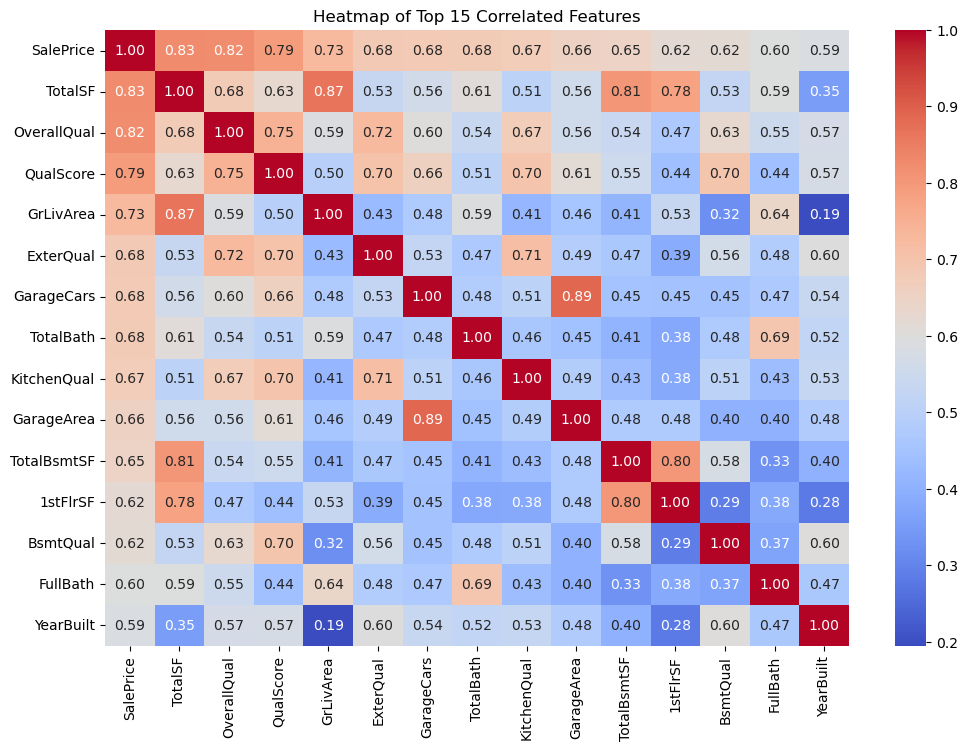

In [6]:
# Get the top 15 positively correlated features with the target variable
top_positive_corr_features = df.corr()['SalePrice'].sort_values(ascending=False).head(15).index

# Select the top correlated features
top_corr_features = df[top_positive_corr_features]

# Plot heatmap of top correlated features
plt.figure(figsize=(12, 8))
sns.heatmap(top_corr_features.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Heatmap of Top 15 Correlated Features')
plt.show()

## 2.2 Top 5 Features which have the highest correlationship with SalePrice

The top 5 features which have the highest correlationship with the objective variable SalePrice are TotalSF (total square feet), OverallQual (rates the overall material and finish of the house), QualScore (sum of all quality features), GrlivArea (above grade (ground) living area square feet) and ExterQual (evaluates the quality of the material on the exterior).

The distribution of those features are shown below.

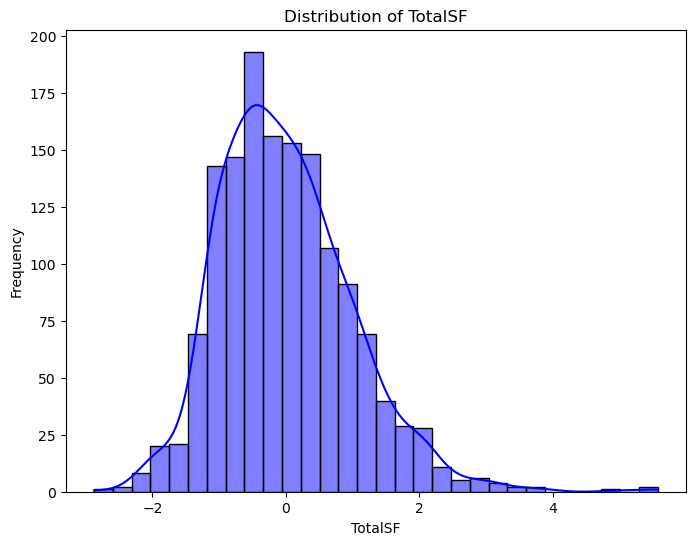

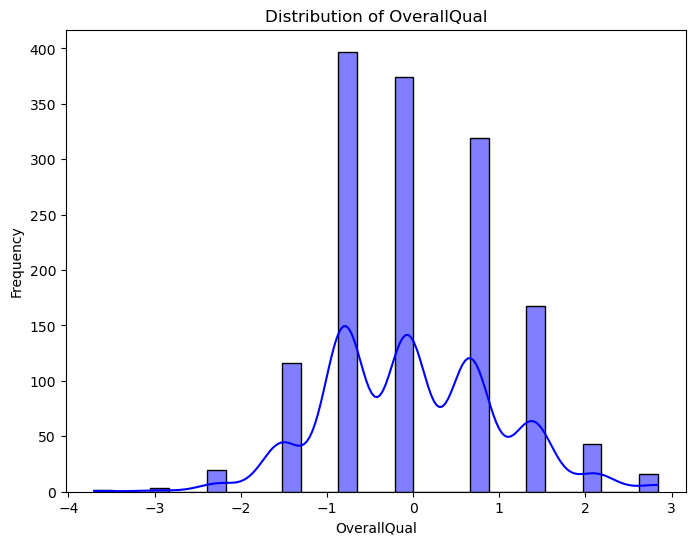

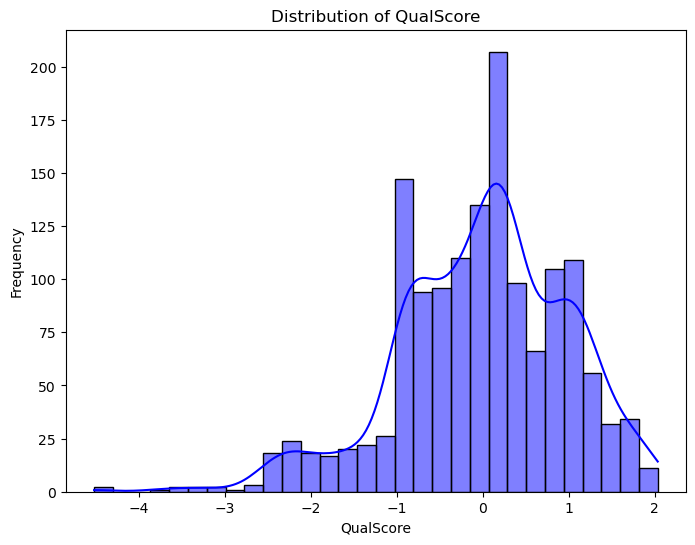

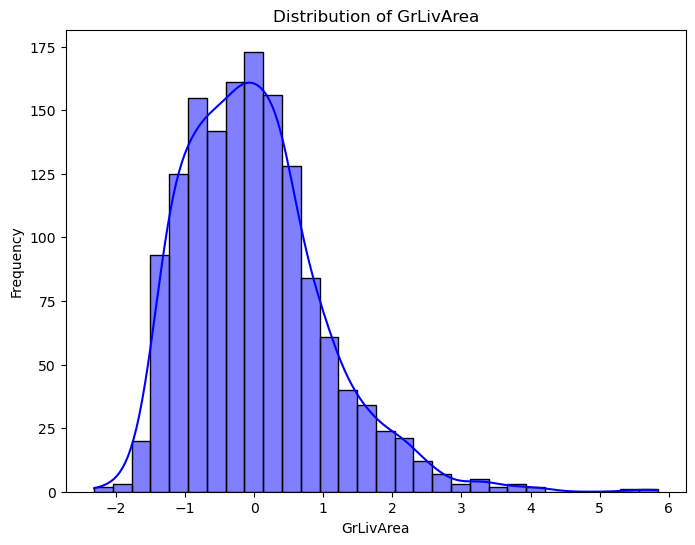

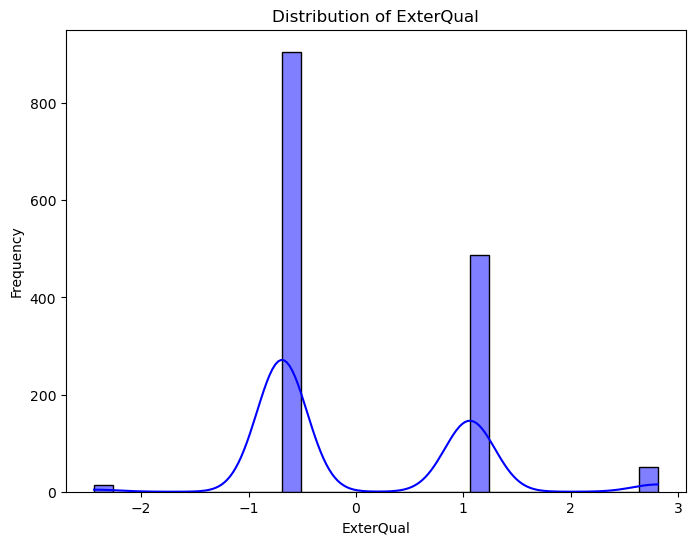

In [14]:
# Get top 5 correlated features
top_5_corr_features = df.corr()['SalePrice'].sort_values(ascending=False).head(6).index[1:]

for feature in top_5_corr_features:
    plt.figure(figsize=(8, 6))
    sns.histplot(df[feature], kde=True, bins=30, color='blue')
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

We also draw the scatter plots of each feature and logarithmic sale price respectively, and add trend lines. They are all positive related.

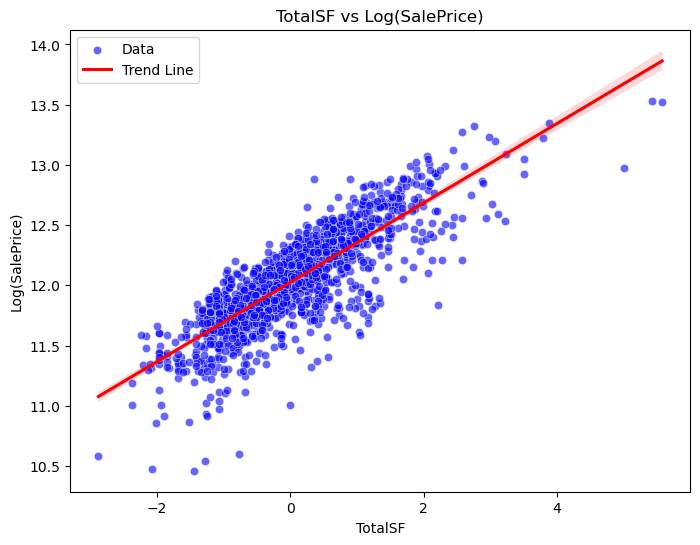

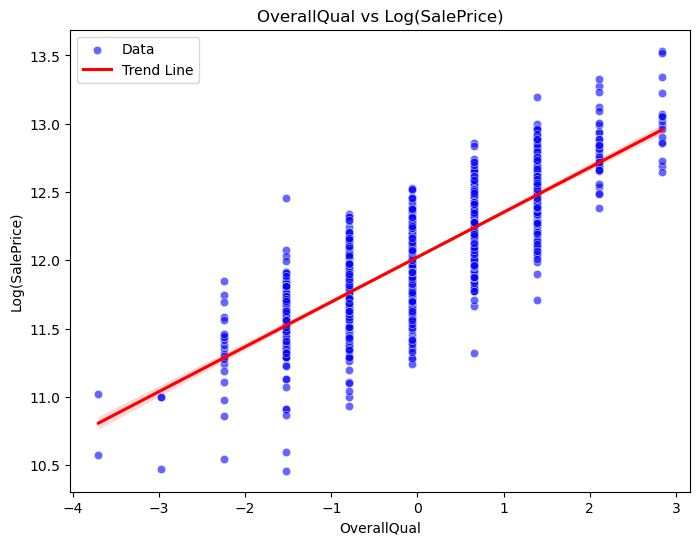

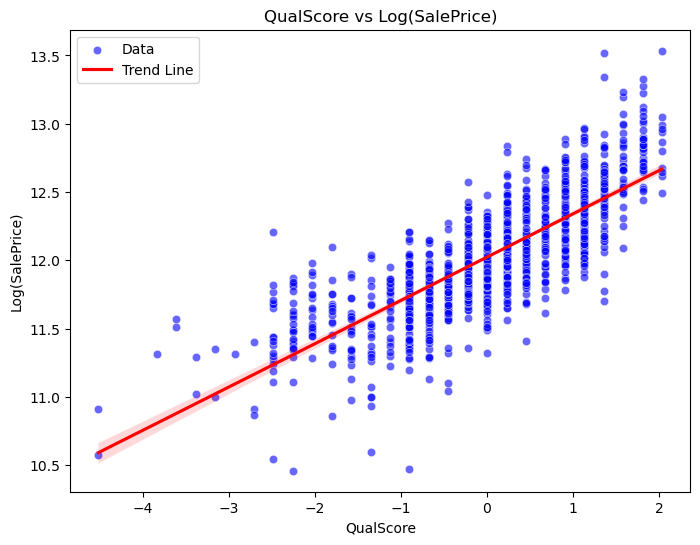

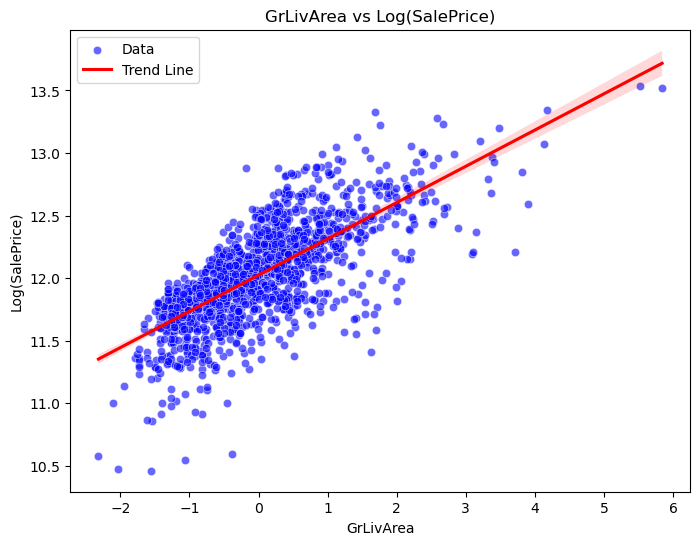

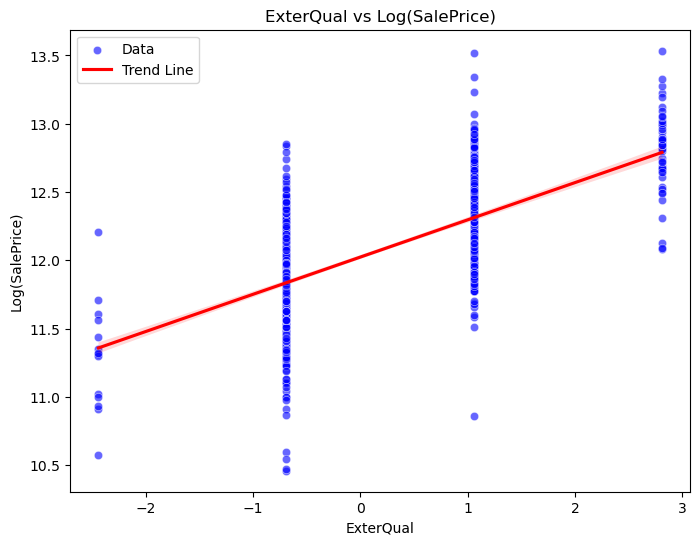

In [15]:
# Draw the scatter plot
for feature in top_5_corr_features:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(x=df[feature], y=df['SalePrice'], alpha=0.6, color='blue', label='Data')
    sns.regplot(x=df[feature], y=df['SalePrice'], scatter=False, color='red', label='Trend Line')
    plt.title(f'{feature} vs Log(SalePrice)')
    plt.xlabel(feature)
    plt.ylabel('Log(SalePrice)')
    plt.legend()
    plt.show()

## 2.3 Numerical Features

Now let's explore the numerical features in our data. The distributions of numerical variables are shown below.

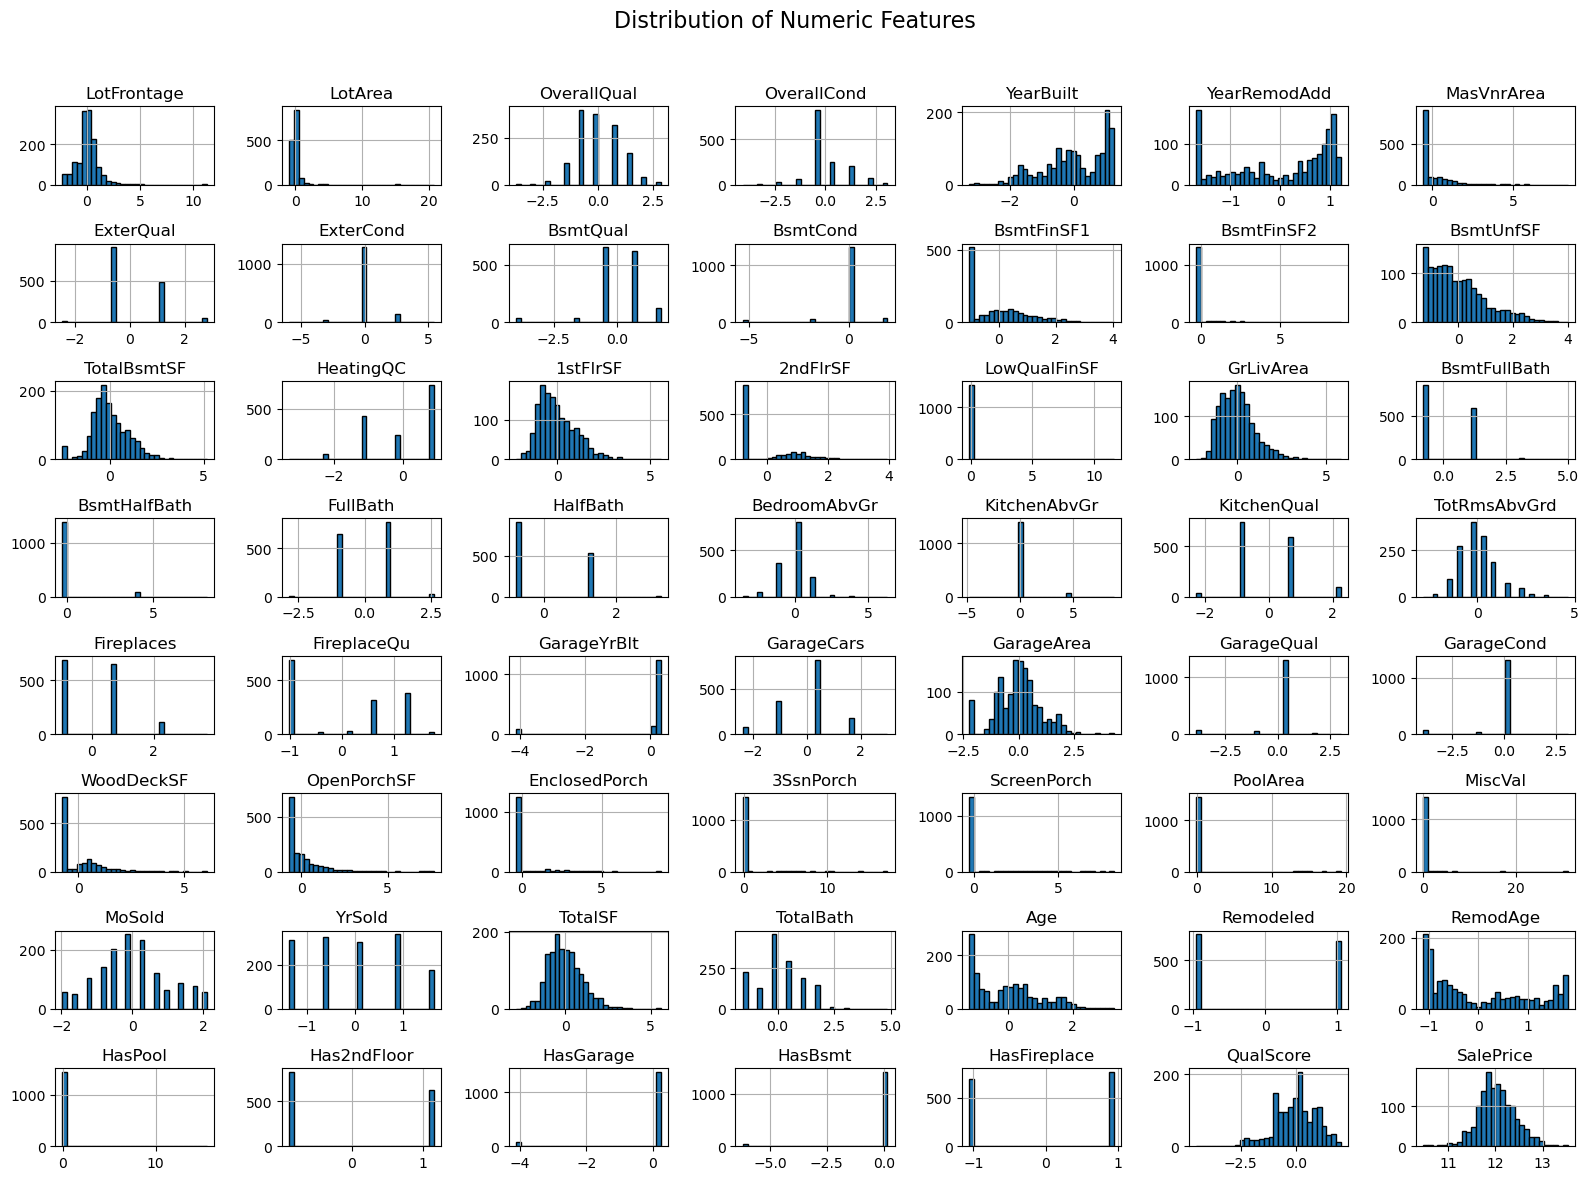

In [16]:
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns
df[numeric_features].hist(figsize=(16, 12), bins=30, edgecolor='black')
plt.suptitle('Distribution of Numeric Features', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 2.4 Principal Component Analysis

Principal Component Analysis (PCA), a classic unsupervised dimensionality - reduction technique, reconstructs original high - dimensional variables into a set of linearly uncorrelated principal components through orthogonal transformation. It significantly reduces dimensionality while maximizing the retention of data variance (i.e., information). This method not only simplifies data structure but also reveals latent patterns hidden among variables.

The boxplot illustrates the relationship between Overall Quality (OverallQual) and the logarithm of house price (Log(SalePrice)). As the OverallQual value increases from 1 to 10, the median and distribution of Log(SalePrice) generally show an upward trend, indicating that the higher the overall quality of the house, the higher the Log(SalePrice) (i.e., the actual house price). 

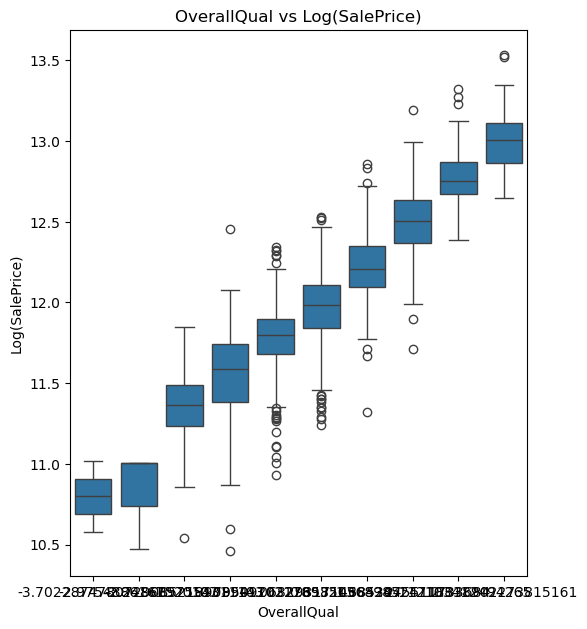

In [17]:
important_features = ['OverallQual']

# Create boxplots for each feature
plt.figure(figsize=(16, 12))
for i, feature in enumerate(important_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=df[feature], y=df['SalePrice'])
    plt.title(f'{feature} vs Log(SalePrice)')
    plt.xlabel(feature)
    plt.ylabel('Log(SalePrice)')

plt.tight_layout()
plt.show()

After the process of PCA, the number of features changed from 256 to 62 with a 95% cumulative explained variance.

In [18]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')
train_data_imputed = imputer.fit_transform(df)
test_data_imputed = imputer.transform(df)

# Applying PCA
print("\nApplying PCA...")
pca = PCA(n_components=0.95)
train_pca = pca.fit_transform(train_data_imputed)
test_pca = pca.transform(test_data_imputed)

# Print the result
print(f"Original number of features: {train_data_imputed.shape[1]}")
print(f"Reduced number of features after PCA: {train_pca.shape[1]}")


Applying PCA...
Original number of features: 256
Reduced number of features after PCA: 62


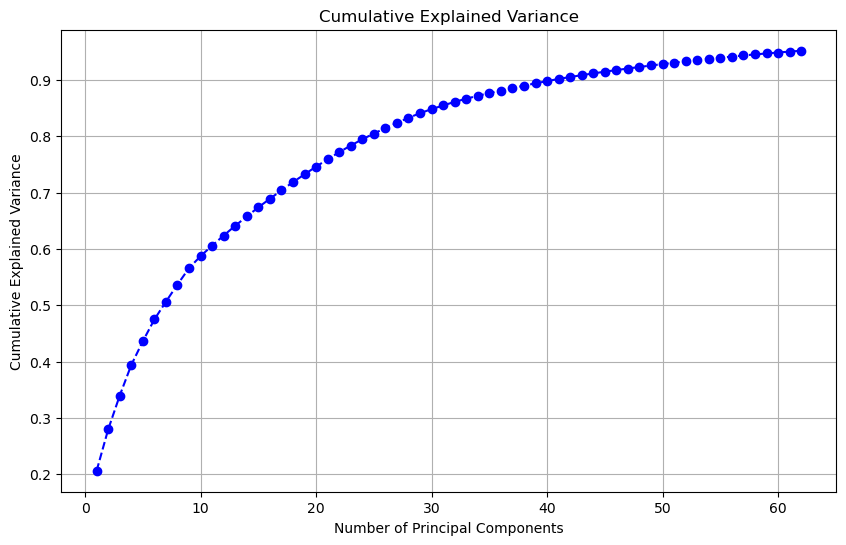

In [19]:
# draw explained variance ratio
explained_variance_ratio = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, marker='o', linestyle='--', color='b')
plt.title('Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid()
plt.show()

The two - dimensional scatter plot of Principal Component Analysis (PCA), showing the distribution of data on the first principal component (Principal Component 1) and the second principal component (Principal Component 2), with the color of points corresponding to the logarithm of house price (Log(SalePrice)). From the graph, the brighter - colored areas (such as yellow) correspond to higher Log(SalePrice), indicating that the house prices represented by these data points are higher; the darker - colored areas (such as purple) correspond to lower Log(SalePrice), that is, the house prices are lower. The distribution of scatter points indicates that Principal Component 1 and Principal Component 2 can distinguish data of different house - price levels to a certain extent, reflecting that while dimensionality reduction, PCA retains key information related to house prices.

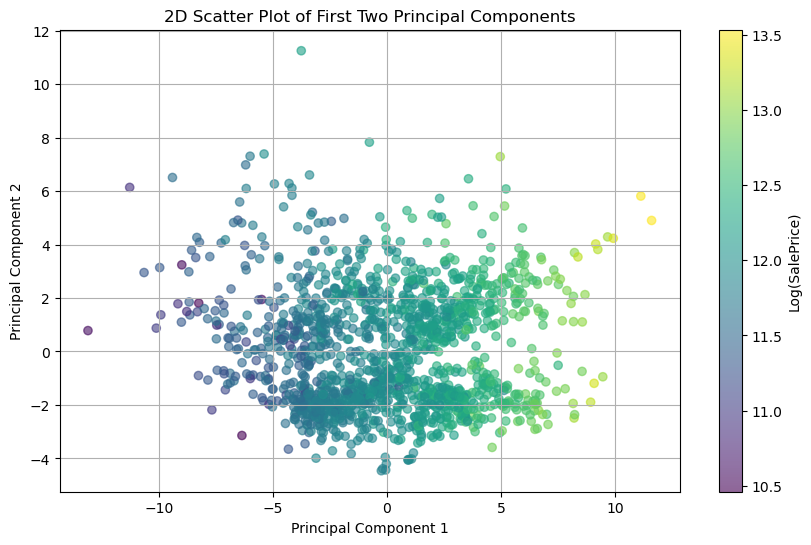

In [20]:
plt.figure(figsize=(10, 6))
plt.scatter(train_pca[:, 0], train_pca[:, 1], alpha=0.6, c=df['SalePrice'], cmap='viridis')
plt.colorbar(label='Log(SalePrice)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('2D Scatter Plot of First Two Principal Components')
plt.grid()
plt.show()

In PC1, features such as QualScore (0.244024) and OverallQual (0.226733) have relatively large weights, contributing significantly to PC1. In PC2, features like 2ndFlrSF (0.370672) and TotRmsAbvGrd (0.357944) have prominent weights, making substantial contributions to PC2. These features play a key role in their respective principal components within the principal - component analysis. 

In [21]:
# Get PCA components and their contributions
pc1_weights = pca.components_[0]
pc2_weights = pca.components_[1]

# Get feature names and sort by contribution
feature_names = df.columns
pc1_contributions = pd.DataFrame({'Feature': feature_names, 'PC1_Weight': pc1_weights}).sort_values(by='PC1_Weight', ascending=False)
pc2_contributions = pd.DataFrame({'Feature': feature_names, 'PC2_Weight': pc2_weights}).sort_values(by='PC2_Weight', ascending=False)

# Display top contributing features for PC1 and PC2
print("PC1 top contributing feature:")
print(pc1_contributions.head(10))

print("\nPC2 top contributing feature:")
print(pc2_contributions.head(10))


PC1 top contributing feature:
        Feature  PC1_Weight
54    QualScore    0.244024
2   OverallQual    0.226733
44      TotalSF    0.219780
31   GarageCars    0.210499
7     ExterQual    0.202926
32   GarageArea    0.198658
26  KitchenQual    0.195386
45    TotalBath    0.192854
9      BsmtQual    0.192458
4     YearBuilt    0.192104

PC2 top contributing feature:
               Feature  PC2_Weight
17            2ndFlrSF    0.370672
50         Has2ndFloor    0.357944
27        TotRmsAbvGrd    0.303812
24        BedroomAbvGr    0.288038
19           GrLivArea    0.283389
23            HalfBath    0.194367
22            FullBath    0.152066
46                 Age    0.149213
25        KitchenAbvGr    0.125046
136  HouseStyle_2Story    0.121973


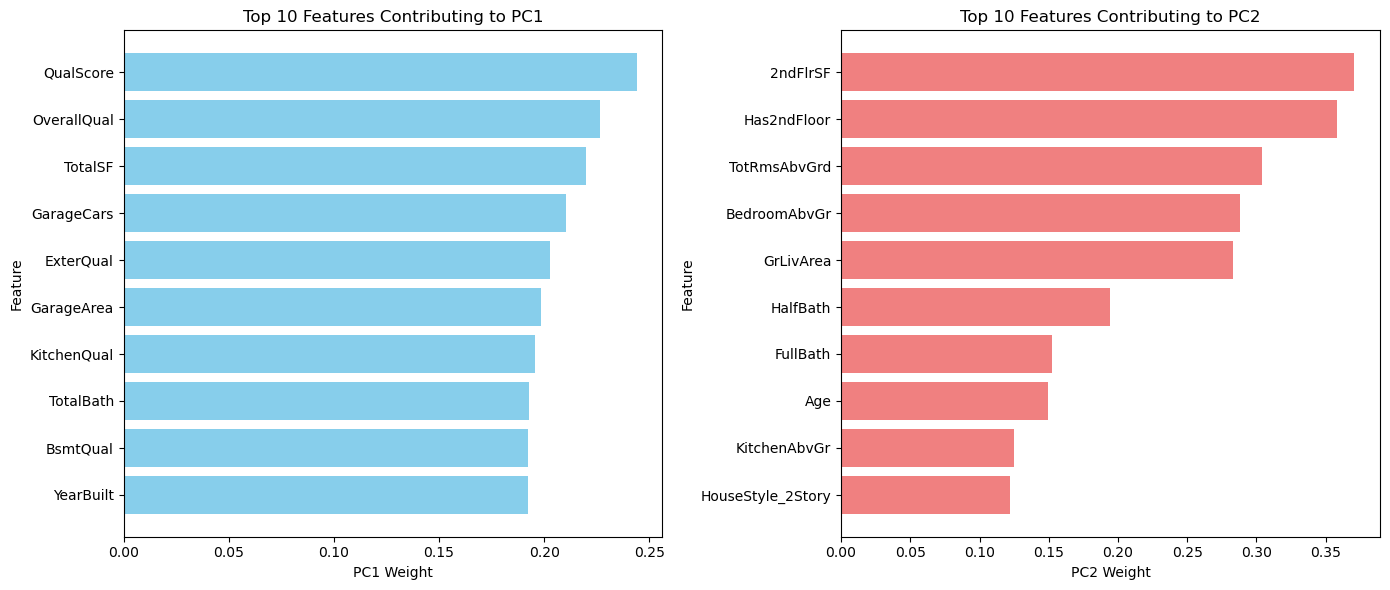

In [22]:
# Get the top 10 contributions for PC1 and PC2
top_pc1_contributions = pc1_contributions.head(10).sort_values(by='PC1_Weight', ascending=True)
top_pc2_contributions = pc2_contributions.head(10).sort_values(by='PC2_Weight', ascending=True)

# Plot the contributions
plt.figure(figsize=(14, 6))

# PC1 contributions
plt.subplot(1, 2, 1)
plt.barh(top_pc1_contributions['Feature'], top_pc1_contributions['PC1_Weight'], color='skyblue')
plt.title('Top 10 Features Contributing to PC1')
plt.xlabel('PC1 Weight')
plt.ylabel('Feature')

# PC2 contributions
plt.subplot(1, 2, 2)
plt.barh(top_pc2_contributions['Feature'], top_pc2_contributions['PC2_Weight'], color='lightcoral')
plt.title('Top 10 Features Contributing to PC2')
plt.xlabel('PC2 Weight')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

Below is a KMeans clustering result graph, showing the distribution of data points in a two - dimensional space composed of the first principal component (Principal Component 1) and the second principal component (Principal Component 2), with different colors representing different clustering clusters (Cluster). It can be seen from the graph that the data points are divided into multiple clusters, and each cluster has a relatively concentrated distribution area in the principal component space. For example, the cluster represented by yellow points is distributed in the higher Principal Component 2 area, while the cluster represented by purple points is concentrated in the lower area of Principal Component 1 and Principal Component 2. This distribution indicates that the KMeans algorithm has successfully grouped the data according to the principal - component features. The data points of different clusters show obvious distinctions in the principal - component space.


Performing KMeans clustering...
Silhouette Score: 0.07


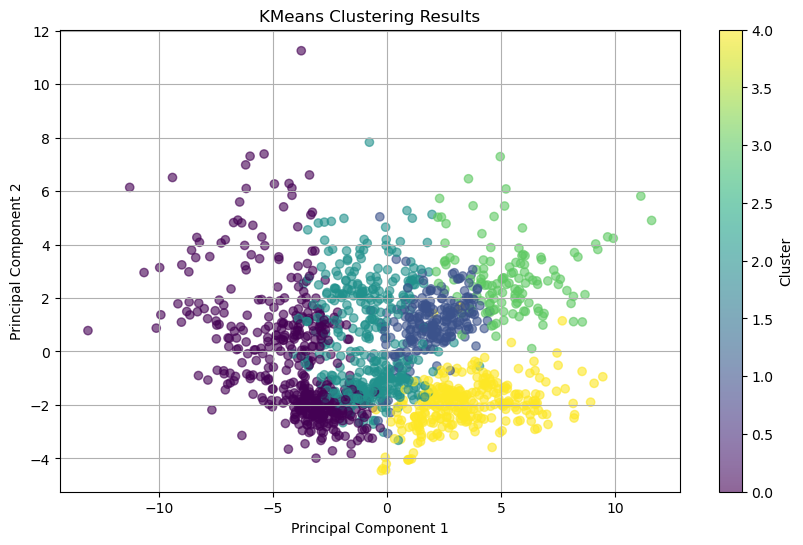

In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# use PCA components for clustering
print("\nPerforming KMeans clustering...")
kmeans = KMeans(n_clusters=5, random_state=42)  # 假设分为 5 个簇
kmeans.fit(train_pca)

# get cluster labels
cluster_labels = kmeans.labels_

# calculate silhouette score
silhouette_avg = silhouette_score(train_pca, cluster_labels)
print(f"Silhouette Score: {silhouette_avg:.2f}")

# put cluster labels back into the original DataFrame
df['Cluster'] = cluster_labels

# visualize clustering results
plt.figure(figsize=(10, 6))
plt.scatter(train_pca[:, 0], train_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6)
plt.colorbar(label='Cluster')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('KMeans Clustering Results')
plt.grid()
plt.show()

Here are the cluster centers in PCA space.

In [13]:
# get cluster centers in PCA space
cluster_centers = pd.DataFrame(kmeans.cluster_centers_, columns=[f'PC{i+1}' for i in range(train_pca.shape[1])])
print("Cluster Centers (in PCA space):")
print(cluster_centers)

df['Cluster'] = cluster_labels

# Summarize clusters
for cluster in range(kmeans.n_clusters):
    print(f"\nCluster {cluster} Summary:")
    cluster_data = df[df['Cluster'] == cluster]
    print(cluster_data.describe())

Cluster Centers (in PCA space):
        PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0 -3.991228 -0.343585 -0.346790 -0.105885 -0.073689 -0.059280  0.361611   
1  1.978435  1.080086 -0.558929 -2.390947 -0.058619 -0.975791 -0.033973   
2 -0.740850  0.444056  1.631827  1.011198  0.386756  0.198624 -0.469325   
3  5.378984  2.746526  0.261549  0.195154 -0.074968 -0.601437  0.189070   
4  3.454563 -1.951966 -1.172129  0.565191 -0.286411  0.807830 -0.044397   

        PC8       PC9      PC10  ...      PC53      PC54      PC55      PC56  \
0  0.055419 -0.276675 -0.028540  ...  0.020129 -0.001301 -0.014309  0.015427   
1 -0.195587  0.251172  0.151763  ... -0.028382 -0.012809 -0.014394  0.052955   
2 -0.269753  0.242542  0.195977  ... -0.010867  0.011565  0.046416 -0.000151   
3  0.045644  0.040288  0.049400  ...  0.138973  0.071755 -0.070707 -0.053655   
4  0.367021 -0.063574 -0.326965  ... -0.056547 -0.033350  0.005648 -0.039473   

       PC57      PC58      PC59     

# 3 Methods

## 3.1 Baseline Model

We run an OLS model firstly as the baseline. Splitting the data randomly into training set (80%) and testing set (20%), we run OLS regressions on house saling price seperately. The RMSE of training set is 0.09 which seems that the model fits well. However, the RMSE of testing set is super big, indicating that an OLS model with 255 explanatory variables could cause a severe problem of overfitting. The OLS model has a weak capacity of generalization to new samples.

Therefore, it is necessary to explore some other methods in machine learning which applied for high dimension data to predicting house sale price in Ames.

In [2]:
import warnings
warnings.filterwarnings('ignore')

X = pd.read_csv('processed_data.csv')
y = pd.read_csv('processed_y.csv')

# Split the data into train set and test set
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [3]:
# Import necessary libraries
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# fit the OLS model
ols_model = LinearRegression()
ols_model.fit(X_train, y_train)

# Make predictions on test data
test_predictions = ols_model.predict(X_test)

# Calculate RMSE
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
print(f"Testing RMSE: {test_rmse:.2f}")

Testing RMSE: 584473185.89


In [4]:
# Make predictions on test data
train_predictions = ols_model.predict(X_train)

# Calculate RMSE
train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
print(f"Training RMSE: {train_rmse:.2f}")

Training RMSE: 0.09


## 3.2 Machine Learning Techniques

To achieve accurate housing - price prediction, this study employs several distinct machine - learning methods, each leveraging its unique strengths. 

Lasso (Least Absolute Shrinkage and Selection Operator) is utilized to conduct regression analysis while addressing multicollinearity through feature selection, identifying the most relevant predictors for price estimation. Decision Tree is applied to model the hierarchical and intuitive relationships between features and housing prices, providing a transparent framework for understanding how different attributes influence prices. Random Forest (RF), as an ensemble of decision trees, is then used to enhance the stability and accuracy of predictions, reducing the overfitting risk inherent in single decision trees. Neural Network, with its exceptional ability to capture complex nonlinear relationships, is employed to uncover intricate patterns within the data that linear or simple nonlinear models might miss. Finally, Gradient Boosting is utilized to iteratively refine predictions by focusing on reducing residuals, thereby improving the overall prediction accuracy. 

We conduct a comprehensive exploration of housing - price prediction from multiple perspectives, enhancing the reliability and validity of the outcomes. 

# 4 Implementation and Results

## 4.1 LASSO

Traditional linear regression methods, such as ordinary least squares, face two critical challenges when dealing with such data: a significantly heightened risk of overfitting and difficulty in selecting truly explanatory features from a vast number of variables. As we testing in Section 3.1, the OLS model has a sever overfitting problem. *The Least Absolute Shrinkage and Selection Operator (LASSO)*, a regression modeling approach incorporating L1 regularization, effectively addresses the issues of variable selection and parameter estimation in high-dimensional settings. By introducing an L1-norm penalty term into the loss function, LASSO can exactly shrink the coefficients of some variables to zero, enabling automatic exclusion of irrelevant variables and producing a sparse model solution. This property not only enhances the model’s generalization ability but also improves interpretability.

The results is shown below. The best alpha we choose based on cross validation is 0.00051. Under this penalty coefficient, the capacity of predicting on test set improves dramatically with a test RMSE 0.122. The LASSO model retains key explanatory variables while inducing sparsity in the coefficient matrix, effectively identifying features significantly associated with the target variable. 

We plot the LASSO regularization path. And get the top 10 most important features: 
1. SaleType_New: 0.107522 (Sale type - new)
2. Neighborhood_Crawfor: 0.096851 (Physical locations within Ames city limits -	Crawford )
3. Neighborhood_StoneBr: 0.090757 (Physical locations within Ames city limits - Stone Brook)
4. MSZoning_FV: 0.079757 (Identifies the general zoning classification of the sale - Floating Village Residential) 
5. Exterior1st_BrkFace: 0.075815 (Exterior covering on house - Brick Face)
6. MSSubClass_160: 0.074853 (Identifies the type of dwelling involved in the sale - 2-STORY PUD - 1946 & NEWER)
7. TotalSF: 0.073905 (Total square feet)
8. GrLivArea: 0.073781 (Above grade (ground) living area square feet)
9. OverallQual: 0.064430 (Rates the overall material and finish of the house)
10. Neighborhood_BrkSide: 0.057471 (Physical locations within Ames city limits)

In [5]:
from sklearn.linear_model import LassoCV, Lasso
from sklearn.model_selection import KFold
from math import sqrt

# Initialize cv and alpha range for LASSO
alphas = np.logspace(-4, 1, 100)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Create LassoCV model
lasso_cv = LassoCV(
    alphas=alphas,
    cv=kfold,
    max_iter=10000,
    tol=0.0001,
    random_state=42
)

# Fit the model
lasso_cv.fit(X_train, y_train)

# Get the best alpha value
best_alpha = lasso_cv.alpha_
print(f"Best alpha value: {best_alpha}")

Best alpha value: 0.000509413801481638


In [6]:
best_lasso = Lasso(alpha=best_alpha, max_iter=10000, random_state=42)
best_lasso.fit(X_train, y_train)

y_pred = best_lasso.predict(X_test)

rmse = sqrt(mean_squared_error(y_test, y_pred))
print(f"Test RMSE: {rmse:.6f}")

Test RMSE: 0.121555



Feature Coefficients:
Feature 1: 0.010693
Feature 2: 0.014192
Feature 3: 0.064430
Feature 4: 0.043653
Feature 7: 0.008254
Feature 8: 0.002717
Feature 9: -0.005698
Feature 10: 0.001936
Feature 11: 0.002916
Feature 12: 0.030585
Feature 13: 0.003689
Feature 16: 0.002872
Feature 17: 0.002517
Feature 19: 0.005845
Feature 20: 0.073781
Feature 21: 0.004196
Feature 22: -0.003141
Feature 24: 0.006026
Feature 25: -0.006481
Feature 26: -0.012550
Feature 27: 0.005846
Feature 28: 0.018910
Feature 29: 0.009154
Feature 32: 0.014893
Feature 33: 0.015279
Feature 34: 0.007478
Feature 36: 0.011809
Feature 37: 0.007962
Feature 38: 0.004139
Feature 39: 0.004574
Feature 40: 0.009601
Feature 41: 0.025980
Feature 42: -0.001405
Feature 43: -0.001505
Feature 44: -0.001897
Feature 45: 0.073905
Feature 46: 0.017888
Feature 47: -0.054700
Feature 48: -0.003100
Feature 49: -0.015719
Feature 50: -0.023953
Feature 53: -0.009577
Feature 55: 0.021467
Feature 56: -0.074853
Feature 59: 0.011285
Feature 60: -0.031017
Feat

<Figure size 1200x600 with 0 Axes>

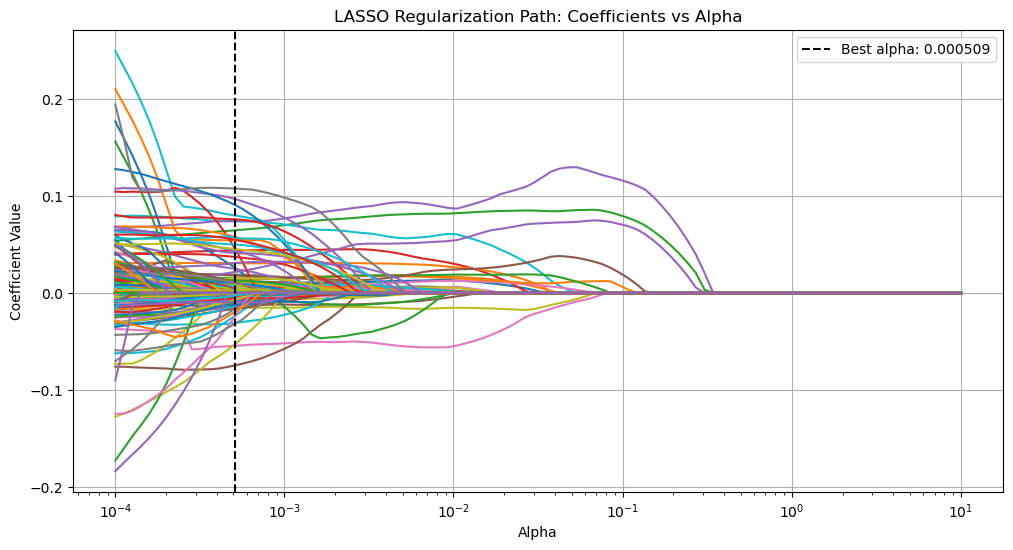

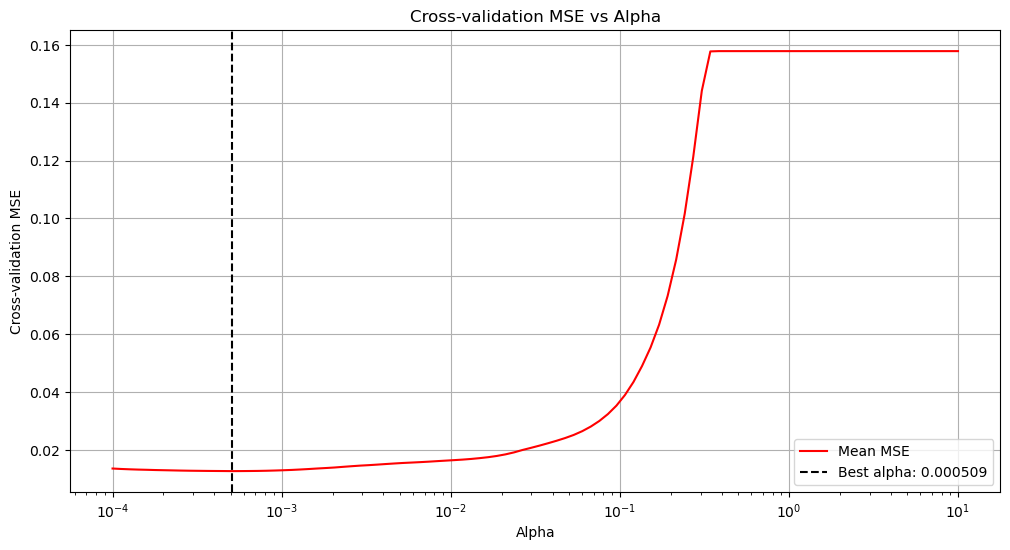

In [46]:
# Plot the regularization path (coefficients vs alpha)
plt.figure(figsize=(12, 6))

# Create alpha range for plotting
alphas_for_plot = np.logspace(-4, 1, 100)
coefs = []

# Train a Lasso model for each alpha value and get coefficients
for a in alphas_for_plot:
    lasso = Lasso(alpha=a, max_iter=10000, random_state=42)
    lasso.fit(X_train, y_train)
    coefs.append(lasso.coef_)

# Convert coefficient list to array
coefs = np.array(coefs)

# Plot how different feature coefficients change with alpha
plt.figure(figsize=(12, 6))
plt.semilogx(alphas_for_plot, coefs)

# Mark the position of the best alpha in the plot
plt.axvline(best_alpha, color='k', linestyle='--', label=f'Best alpha: {best_alpha:.6f}')

# Add labels and title
plt.xlabel('Alpha')
plt.ylabel('Coefficient Value')
plt.title('LASSO Regularization Path: Coefficients vs Alpha')
plt.axis('tight')
plt.legend()
plt.grid(True)

# Display the coefficients of the best model
print("\nFeature Coefficients:")
for i, coef in enumerate(best_lasso.coef_):
    if coef != 0:  # Only show non-zero coefficients
        print(f"Feature {i+1}: {coef:.6f}")

# Calculate the number of non-zero coefficients (number of features selected by the model)
n_selected_features = np.sum(best_lasso.coef_ != 0)
print(f"\nNumber of features selected by the model: {n_selected_features}")

# Cross-validation MSE vs alpha curve
plt.figure(figsize=(12, 6))
plt.semilogx(lasso_cv.alphas_, lasso_cv.mse_path_.mean(axis=1), 'r-', label='Mean MSE')
plt.axvline(best_alpha, color='k', linestyle='--', label=f'Best alpha: {best_alpha:.6f}')
plt.xlabel('Alpha')
plt.ylabel('Cross-validation MSE')
plt.title('Cross-validation MSE vs Alpha')
plt.legend()
plt.grid(True)
plt.show()

In [7]:
# Get feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': np.abs(best_lasso.coef_)
})

# Sort by importance
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

# Print the top 10 most important features
print("\nThe top 10 most important features:")
for i, (feature, importance) in enumerate(zip(feature_importance['Feature'][:10], feature_importance['Importance'][:10])):
    print(f"{i+1}. {feature}: {importance:.6f}")

# Get features with non-zero coefficients
selected_features = feature_importance[feature_importance['Importance'] > 0]['Feature'].tolist()

# Print the number of selected features
print(f"{len(selected_features)} features are selected")

# Create a training set and test set only containing selected features
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

# Save the selected feature list
selected_features_df = pd.DataFrame({'Feature': selected_features})
selected_features_df.to_csv('lasso_selected_features.csv', index=False)


The top 10 most important features:
1. SaleType_New: 0.107522
2. Neighborhood_Crawfor: 0.096851
3. Neighborhood_StoneBr: 0.090757
4. MSZoning_FV: 0.079757
5. Exterior1st_BrkFace: 0.075815
6. MSSubClass_160: 0.074853
7. TotalSF: 0.073905
8. GrLivArea: 0.073781
9. OverallQual: 0.064430
10. Neighborhood_BrkSide: 0.057471
104 features are selected


## 4.2 Tree and Random Forest

Regression trees, as nonparametric methods, recursively partition the feature space into homogeneous regions, presenting predictive rules in an intuitive tree structure. This makes them interpretable and effective for handling nonlinearity. However, individual trees are prone to overfitting and exhibit limited generalization. Random forests, an ensemble learning approach, address these limitations by constructing multiple regression trees based on bootstrap samples and introducing random feature selection. This strategy significantly reduces model variance, enhancing prediction stability and accuracy. Random forests not only handle high-dimensional data and complex interactions but also quantify feature importance.

We conducted the training and parameter tuning for the Regression Tree and Random Forest models. During the parameter tuning process of the Regression Tree model, 180 candidate parameter combinations were evaluated through 5 - fold cross - validation, with a total of 900 fits completed. The final determined best parameters are: `criterion: absolute_error`, `max_depth: 9`, `min_samples_leaf: 4`, `min_samples_split: 10`. Under these parameters, the cross - validation root - mean - square error (RMSE) of the Decision Tree is 0.1807, the test set RMSE is 0.1868, the mean absolute error (MAE) is 0.1248, and the coefficient of determination (R²) is 0.7930.  

After tuning, the best parameters of the Random Forest model are: `bootstrap: True`, `max_depth: None`, `min_samples_leaf: 1`, `min_samples_split: 2`, `n_estimators: 200`. Its cross - validation RMSE is 0.1380, the test set RMSE drops to 0.1437, the MAE is 0.0944, and R² increases to 0.8776, with overall performance superior to the Decision Tree model. Additionally, the Feature Importances analysis of the Random Forest shows that `TotalSF` (0.3510) and `OverallQual` (0.3404) are features that have a greater impact on the model, while features such as `Age` (0.0081) and `RemodAge` (0.0077) have relatively lower importance. This indicates that the Random Forest not only has an advantage in prediction accuracy but also can effectively quantify the contribution of each feature, providing more abundant information for model interpretation.  

In [8]:
if hasattr(X_train, 'values'):
    X_train_array = X_train.values
else:
    X_train_array = np.array(X_train)

if hasattr(y_train, 'values'):
    y_train_array = y_train.values.ravel()
else:
    y_train_array = np.array(y_train).ravel()

if hasattr(X_test, 'values'):
    X_test_array = X_test.values
else:
    X_test_array = np.array(X_test)

if hasattr(y_test, 'values'):
    y_test_array = y_test.values.ravel()
else:
    y_test_array = np.array(y_test).ravel()

In [17]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Decision Tree Model with Cross-Validation
print("Starting Decision Tree regression model training and parameter tuning...")

# Define decision tree parameter grid
param_grid_dt = {
    'max_depth': [3, 5, 7, 9, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['squared_error', 'friedman_mse', 'absolute_error', 'poisson']
}
# Create decision tree regressor
dt = DecisionTreeRegressor(random_state=42)

# Use grid search for cross-validation
grid_search_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid_dt,
    cv=5,
    scoring='neg_mean_squared_error',  # Use negative mean squared error as scoring metric
    verbose=1,
    n_jobs=-1
)

# Fit the model
grid_search_dt.fit(X_train_array, y_train_array)

# Print best parameters and scores
print("Decision Tree best parameters:", grid_search_dt.best_params_)
print("Decision Tree best cross-validation score (RMSE):", np.sqrt(-grid_search_dt.best_score_))

# Create Decision Tree model with best parameters
best_dt = grid_search_dt.best_estimator_

# Evaluate model on test set
y_pred_dt = best_dt.predict(X_test)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
mae_dt = mean_absolute_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print(f"Decision Tree test RMSE: {rmse_dt:.4f}")
print(f"Decision Tree test MAE: {mae_dt:.4f}")
print(f"Decision Tree test R²: {r2_dt:.4f}")

# 2. Random Forest Model with Cross-Validation
print("\nStarting Random Forest regression model training and parameter tuning...")

# Define Random Forest parameter grid
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True]
}

# Create Random Forest regressor
rf = RandomForestRegressor(random_state=42)

# Use grid search for cross-validation
grid_search_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring='neg_mean_squared_error',
    verbose=1,
    n_jobs=-1
)

# Fit the model
grid_search_rf.fit(X_train_array, y_train_array)

# Print best parameters and scores
print("Random Forest best parameters:", grid_search_rf.best_params_)
print("Random Forest best cross-validation score (RMSE):", np.sqrt(-grid_search_rf.best_score_))

# Create Random Forest model with best parameters
best_rf = grid_search_rf.best_estimator_

# Evaluate model on test set
y_pred_rf = best_rf.predict(X_test)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random Forest test RMSE: {rmse_rf:.4f}")
print(f"Random Forest test MAE: {mae_rf:.4f}")
print(f"Random Forest test R²: {r2_rf:.4f}")

# Feature importance
feature_importances = best_rf.feature_importances_
feature_names = X_train.columns if hasattr(X_train, 'columns') else [f"feature_{i}" for i in range(X_train.shape[1])]
sorted_indices = np.argsort(feature_importances)[::-1]

print("\nFeature Importances (Random Forest):")
for i in sorted_indices[:10]:
    print(f"{feature_names[i]}: {feature_importances[i]:.4f}")

Starting Decision Tree regression model training and parameter tuning...
Fitting 5 folds for each of 180 candidates, totalling 900 fits
Decision Tree best parameters: {'criterion': 'absolute_error', 'max_depth': 9, 'min_samples_leaf': 4, 'min_samples_split': 10}
Decision Tree best cross-validation score (RMSE): 0.18073840436803146
Decision Tree test RMSE: 0.1868
Decision Tree test MAE: 0.1248
Decision Tree test R²: 0.7930

Starting Random Forest regression model training and parameter tuning...
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Random Forest best parameters: {'bootstrap': True, 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Random Forest best cross-validation score (RMSE): 0.13801114830180083
Random Forest test RMSE: 0.1437
Random Forest test MAE: 0.0944
Random Forest test R²: 0.8776

Feature Importances (Random Forest):
TotalSF: 0.3510
OverallQual: 0.3404
QualScore: 0.1033
GrLivArea: 0.0148
TotalBath: 0.0121
GarageAr

From the diagram below, we can tell that Random Forest model is better than Regression Tree model in predicting house saling price no matter in which metrics we refer to. The RMSE and MAE of Random Forest are both higher than Regression Tree, and R^2 is higher either. 

As can be seen from the learning curves comparison chart, the Random Forest model outperforms the Decision Tree model in both training and validation. The training RMSE of the Random Forest remains consistently low, and the gap between training and validation RMSE is smaller, demonstrating stronger generalization ability. As the number of training examples increases, the Random Forest’s stability and prediction performance are more prominent, enabling it to better adapt to different scales of training data. 

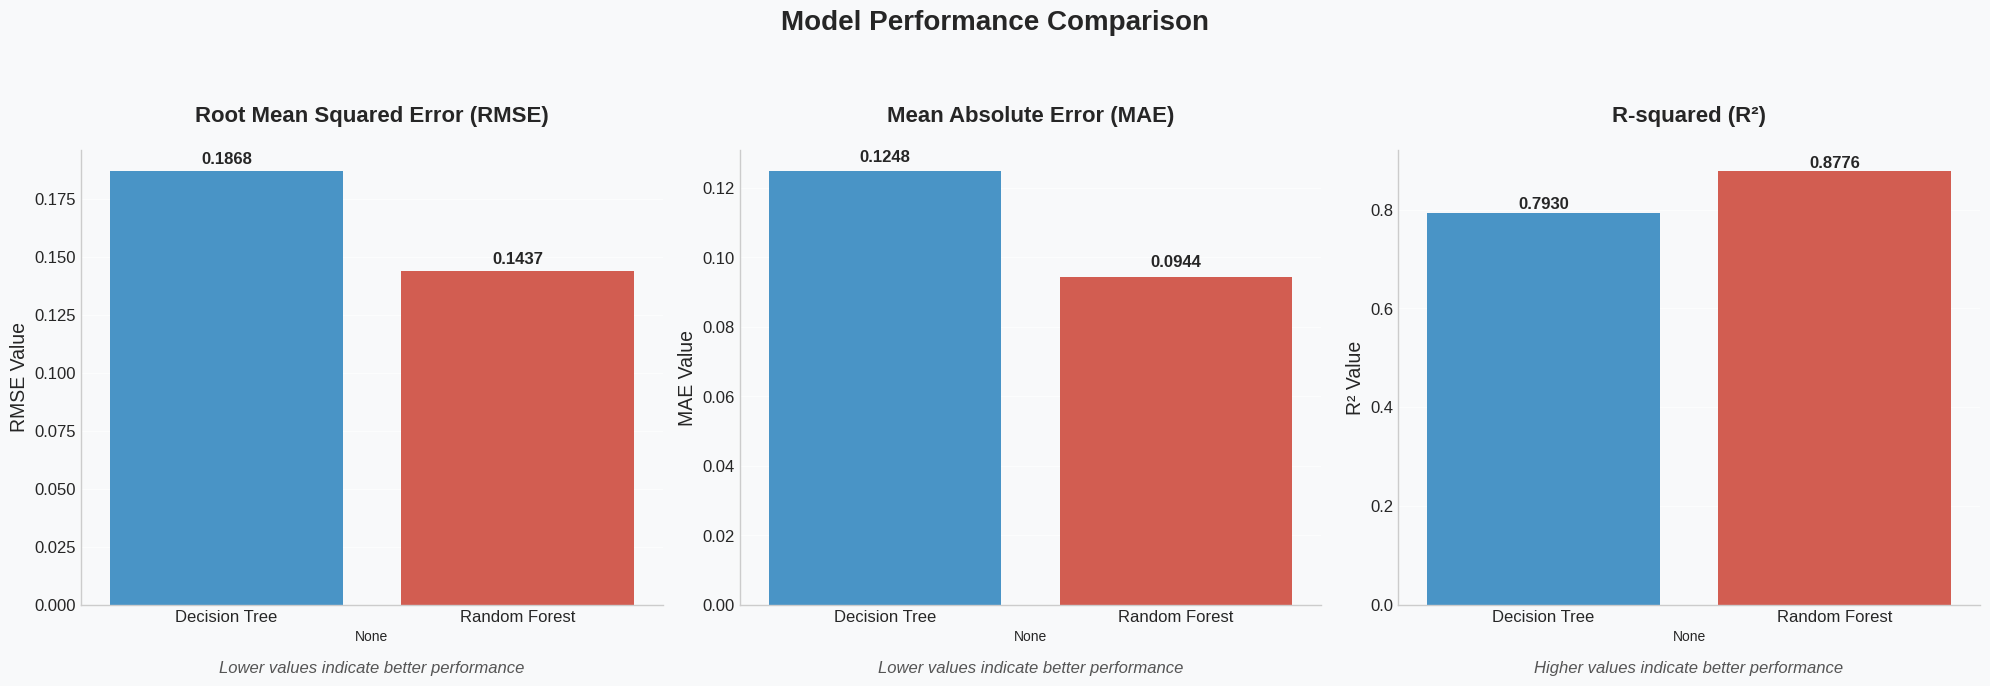

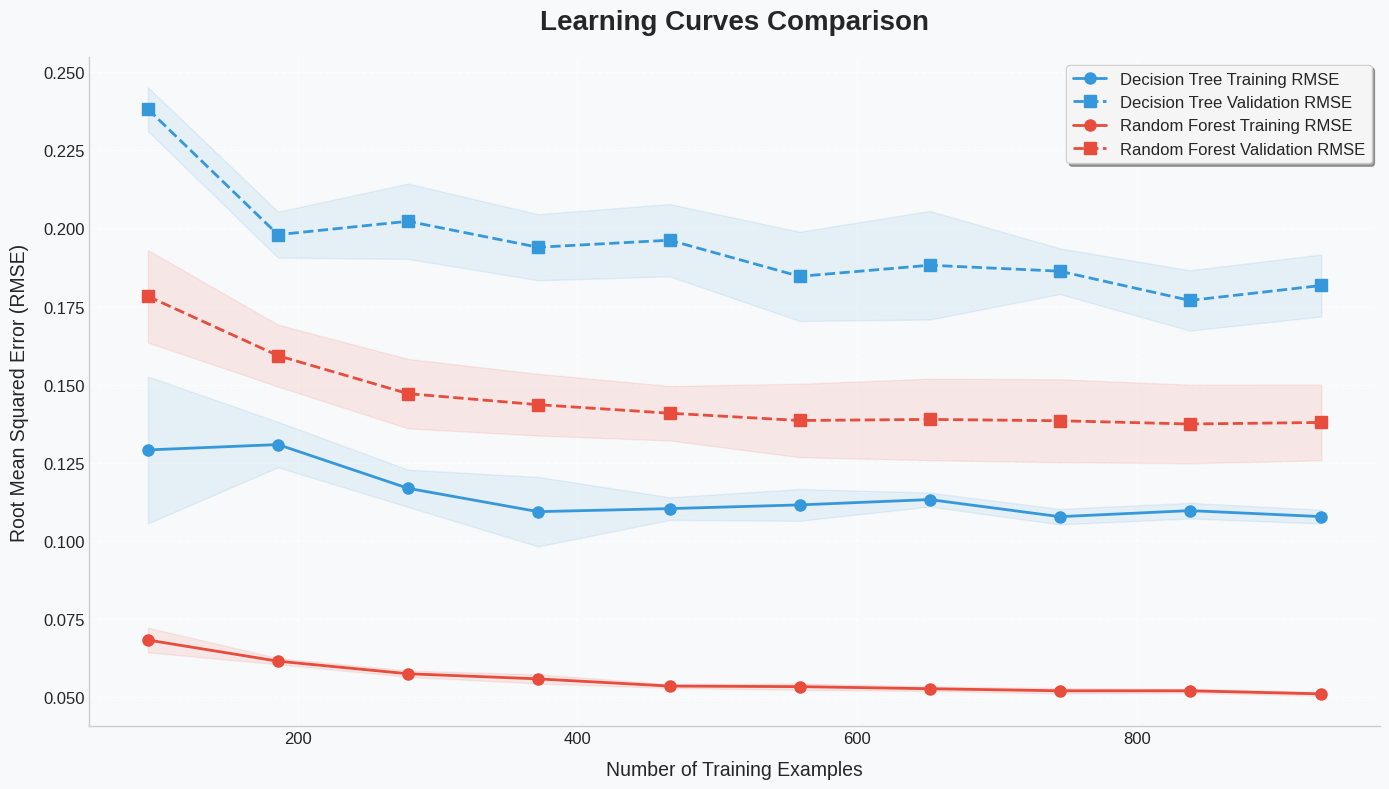

In [23]:
from sklearn.tree import plot_tree
from sklearn.model_selection import learning_curve
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("colorblind") 

model_colors = ["#3498db", "#e74c3c"] 

def compare_models_enhanced(models_dict, X_test, y_test):
    metrics = {
        'RMSE': [],
        'MAE': [],
        'R²': []
    }
    model_names = []
    
    for name, model in models_dict.items():
        y_pred = model.predict(X_test)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        mae = mean_absolute_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        
        metrics['RMSE'].append(rmse)
        metrics['MAE'].append(mae)
        metrics['R²'].append(r2)
        model_names.append(name)
    
    # Create dataframe for visualization
    metrics_df = pd.DataFrame(metrics, index=model_names)
    
    # Create comparison charts with consistent styling
    fig, axes = plt.subplots(1, 3, figsize=(20, 7))
    fig.suptitle('Model Performance Comparison', fontsize=20, y=1.05, fontweight='bold')
    
    # Add background color for better visual appeal
    fig.patch.set_facecolor('#f8f9fa')
    
    # Common styling for all subplots
    for ax in axes:
        ax.set_facecolor('#f8f9fa')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('#cccccc')
        ax.spines['bottom'].set_color('#cccccc')
        ax.grid(color='white', linestyle='-', linewidth=1, alpha=0.7)
    
    # RMSE - Lower is better
    bar1 = sns.barplot(x=metrics_df.index, y=metrics_df['RMSE'], ax=axes[0], palette=model_colors)
    axes[0].set_title('Root Mean Squared Error (RMSE)', fontsize=16, pad=20, fontweight='bold')
    axes[0].set_ylabel('RMSE Value', fontsize=14)
    axes[0].tick_params(axis='x', labelsize=12, rotation=0)
    axes[0].tick_params(axis='y', labelsize=12)
    
    # Add value labels with improved formatting
    for i, v in enumerate(metrics_df['RMSE']):
        axes[0].text(i, v + 0.002, f'{v:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    # Add explanatory note
    axes[0].text(0.5, -0.15, 'Lower values indicate better performance', 
                 transform=axes[0].transAxes, ha='center', fontsize=12, 
                 style='italic', color='#555555')
    
    # MAE - Lower is better
    sns.barplot(x=metrics_df.index, y=metrics_df['MAE'], ax=axes[1], palette=model_colors)
    axes[1].set_title('Mean Absolute Error (MAE)', fontsize=16, pad=20, fontweight='bold')
    axes[1].set_ylabel('MAE Value', fontsize=14)
    axes[1].tick_params(axis='x', labelsize=12, rotation=0)
    axes[1].tick_params(axis='y', labelsize=12)
    
    for i, v in enumerate(metrics_df['MAE']):
        axes[1].text(i, v + 0.002, f'{v:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    axes[1].text(0.5, -0.15, 'Lower values indicate better performance', 
                 transform=axes[1].transAxes, ha='center', fontsize=12, 
                 style='italic', color='#555555')
    
    # R² - Higher is better
    sns.barplot(x=metrics_df.index, y=metrics_df['R²'], ax=axes[2], palette=model_colors)
    axes[2].set_title('R-squared (R²)', fontsize=16, pad=20, fontweight='bold')
    axes[2].set_ylabel('R² Value', fontsize=14)
    axes[2].tick_params(axis='x', labelsize=12, rotation=0)
    axes[2].tick_params(axis='y', labelsize=12)
    
    for i, v in enumerate(metrics_df['R²']):
        axes[2].text(i, v + 0.002, f'{v:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    axes[2].text(0.5, -0.15, 'Higher values indicate better performance', 
                 transform=axes[2].transAxes, ha='center', fontsize=12, 
                 style='italic', color='#555555')
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.85, bottom=0.2)
    
    return fig

def plot_learning_curves_enhanced(models_dict, X_train, y_train, cv=5, train_sizes=np.linspace(0.1, 1.0, 10)):
    """
    Plot enhanced learning curves for multiple models
    
    Parameters:
    - models_dict: Dictionary with model names and objects
    - X_train: Training features
    - y_train: Training labels
    - cv: Cross-validation folds
    - train_sizes: Array of training set size proportions
    """
    fig = plt.figure(figsize=(14, 8))
    fig.patch.set_facecolor('#f8f9fa')
    
    colors = ["#3498db", "#e74c3c"]  # Blue for Decision Tree, Red for Random Forest
    line_styles = ['-', '--']
    
    for i, (name, model) in enumerate(models_dict.items()):
        train_sizes_abs, train_scores, test_scores = learning_curve(
            model, X_train, y_train, cv=cv, n_jobs=-1, train_sizes=train_sizes,
            scoring='neg_mean_squared_error')
        
        # Calculate mean and standard deviation
        train_scores_mean = -np.mean(train_scores, axis=1)
        train_scores_std = np.std(train_scores, axis=1)
        test_scores_mean = -np.mean(test_scores, axis=1)
        test_scores_std = np.std(test_scores, axis=1)
        
        # Calculate RMSE
        train_rmse_mean = np.sqrt(train_scores_mean)
        test_rmse_mean = np.sqrt(test_scores_mean)
        train_rmse_std = train_scores_std / (2 * np.sqrt(train_scores_mean))
        test_rmse_std = test_scores_std / (2 * np.sqrt(test_scores_mean))
        
        # Plot learning curves with custom styling
        plt.fill_between(train_sizes_abs, train_rmse_mean - train_rmse_std,
                         train_rmse_mean + train_rmse_std, alpha=0.1, color=colors[i])
        plt.fill_between(train_sizes_abs, test_rmse_mean - test_rmse_std,
                         test_rmse_mean + test_rmse_std, alpha=0.1, color=colors[i])
        plt.plot(train_sizes_abs, train_rmse_mean, 'o-', color=colors[i], linestyle=line_styles[0],
                 linewidth=2, markersize=8, label=f"{name} Training RMSE")
        plt.plot(train_sizes_abs, test_rmse_mean, 's-', color=colors[i], linestyle=line_styles[1],
                 linewidth=2, markersize=8, label=f"{name} Validation RMSE")
    
    # Enhance plot styling
    plt.title("Learning Curves Comparison", fontsize=20, pad=20, fontweight='bold')
    plt.xlabel("Number of Training Examples", fontsize=14, labelpad=10)
    plt.ylabel("Root Mean Squared Error (RMSE)", fontsize=14, labelpad=10)
    
    # Custom legend with shadow and rounded corners
    legend = plt.legend(loc="upper right", fontsize=12, frameon=True, fancybox=True, 
                       framealpha=0.9, shadow=True, bbox_to_anchor=(1, 1))
    frame = legend.get_frame()
    frame.set_facecolor('white')
    frame.set_edgecolor('#cccccc')
    
    # Remove top and right spines
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_color('#cccccc')
    plt.gca().spines['bottom'].set_color('#cccccc')
    
    # Set grid styling
    plt.grid(color='white', linestyle='-', linewidth=1, alpha=0.7)
    plt.gca().set_facecolor('#f8f9fa')
    
    # Add grid lines and tick parameters
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tick_params(axis='both', which='major', labelsize=12)
    
    plt.tight_layout()
    
    return plt

fig1 = compare_models_enhanced({'Decision Tree': best_dt, 'Random Forest': best_rf}, X_test_array, y_test_array)
#fig1.savefig('enhanced_model_comparison.png', dpi=300, bbox_inches='tight')

fig2 = plot_learning_curves_enhanced({'Decision Tree': best_dt, 'Random Forest': best_rf}, X_train_array, y_train_array)
# fig2.savefig('enhanced_learning_curves.png', dpi=300, bbox_inches='tight')

Below are the plots of learning curve of the Decision Tree Regressor and Random Forest Regressor, with the vertical axis being the score (R²) and the horizontal axis the number of training examples. 

The training score (red) of Decision Tree model starts at approximately 0.88, then gradually rises and approaches 0.93 with minimal fluctuations, indicating improving fitting effects on the training set. The cross - validation score (blue) starts at about 0.63 and later fluctuates upward to around 0.78. There is a significant gap between the training score and the cross - validation score, with the former consistently higher than the latter, suggesting that the Decision Tree model performs well on the training set but has insufficient generalization ability, exhibiting overfitting.

For Random Forest, the training score (red) starts at approximately 0.96, then slowly rises and approaches 0.98 with minimal fluctuations, indicating a good and stable fitting effect on the training set. The cross - validation score (blue) starts at about 0.8 and gradually rises to around 0.875. The gap between the training score and the cross - validation score is relatively small, and both values are relatively high, indicating that the Random Forest model has a good fit on the training set and strong generalization ability, with no obvious overfitting and overall stable and excellent performance

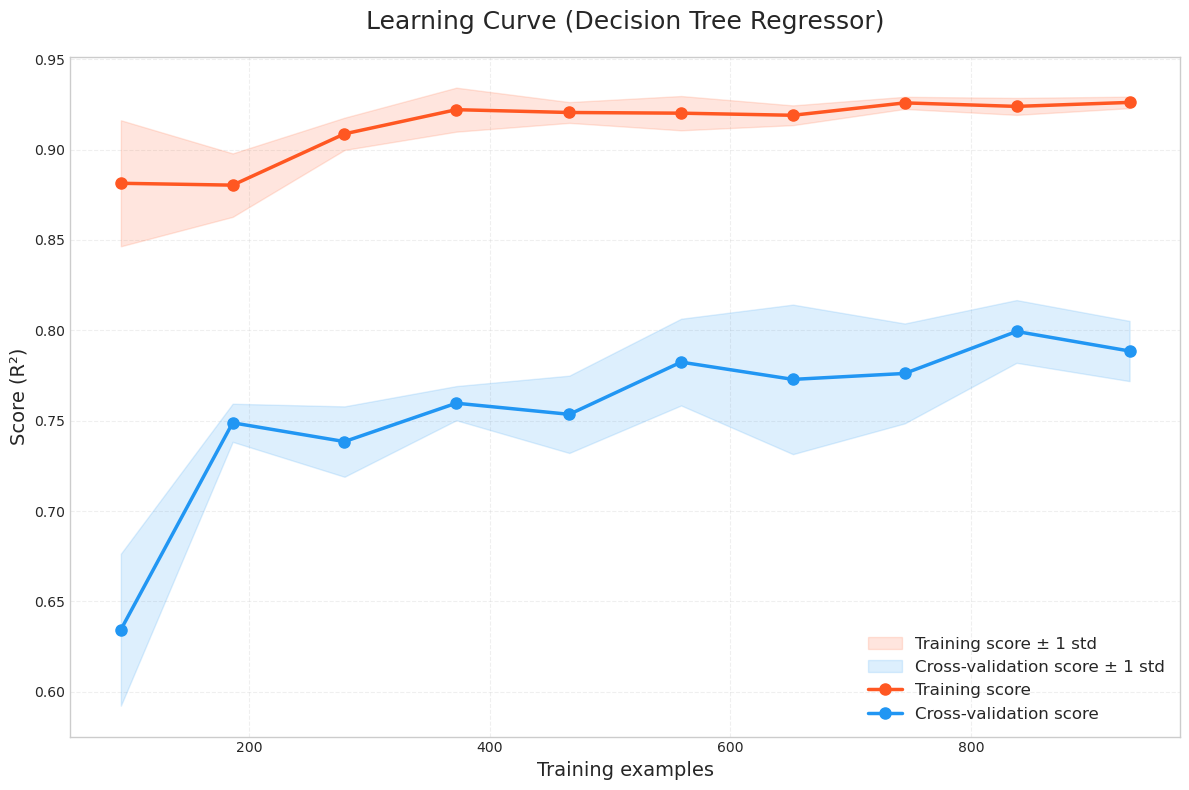

Generating improved learning curve for Random Forest model...


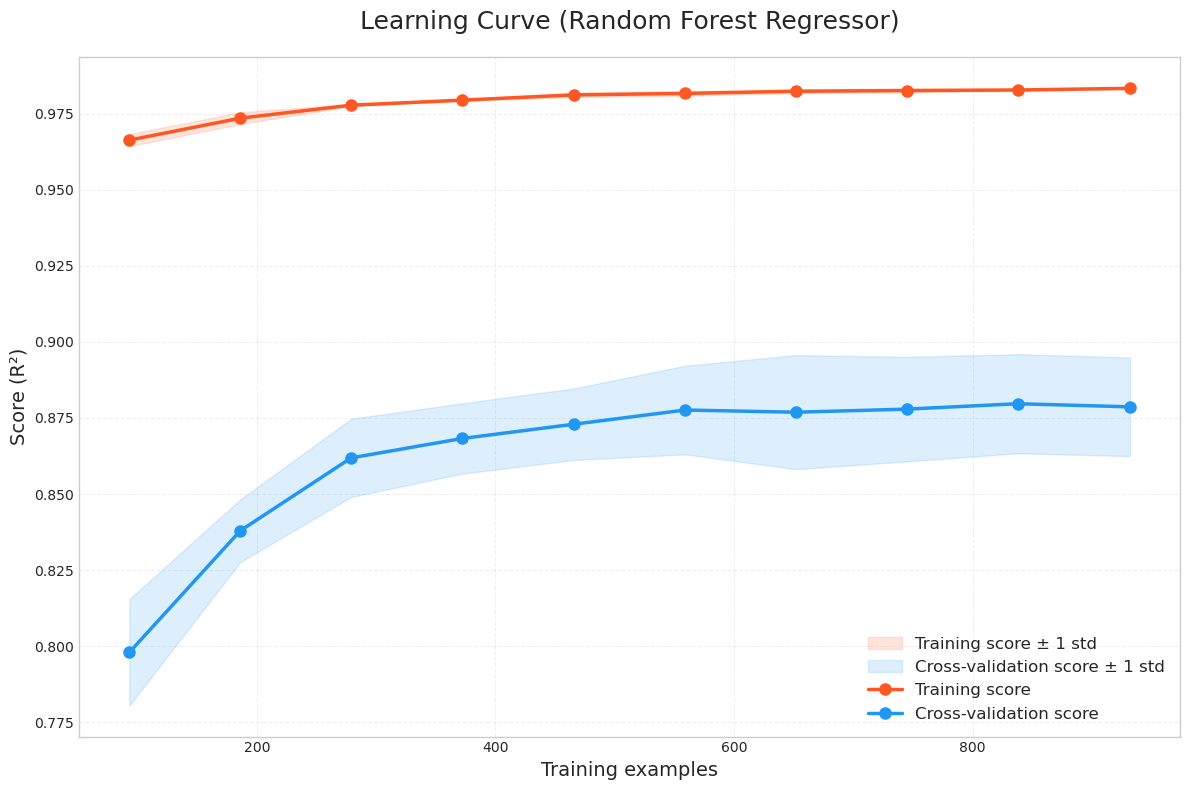

In [24]:
from sklearn.model_selection import learning_curve
from sklearn.metrics import make_scorer

def plot_learning_curve(estimator, X, y, title, ylim=None, cv=5,
                        n_jobs=-1, train_sizes=np.linspace(.1, 1.0, 10),
                        metric="r2"):
    sns.set_style("whitegrid")
    
    plt.figure(figsize=(12, 8))
    plt.title(title, fontsize=18, pad=20)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.xlabel("Training examples", fontsize=14)
    
    if metric == "r2":
        scoring = "r2"
        plt.ylabel("Score (R²)", fontsize=14)
        higher_is_better = True
    elif metric == "rmse":
        rmse_scorer = make_scorer(lambda y, y_pred: np.sqrt(mean_squared_error(y, y_pred)), 
                                 greater_is_better=False)
        scoring = rmse_scorer
        plt.ylabel("RMSE", fontsize=14)
        higher_is_better = False
    
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes,
        scoring=scoring)
    
    if metric == "rmse":
        train_scores = -train_scores
        test_scores = -test_scores
    
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)
    
    train_color = "#FF5722"
    test_color = "#2196F3"
    
    # Add shadow effect
    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.15, color=train_color,
                     label="Training score ± 1 std")
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.15, color=test_color,
                     label="Cross-validation score ± 1 std")
    
    # Main lines
    plt.plot(train_sizes, train_scores_mean, 'o-', color=train_color, label="Training score", 
             linewidth=2.5, markersize=8)
    plt.plot(train_sizes, test_scores_mean, 'o-', color=test_color, label="Cross-validation score", 
             linewidth=2.5, markersize=8)
    
    # Add grid lines
    plt.grid(True, linestyle='--', alpha=0.3)
    
    # Better legend
    plt.legend(loc="lower right" if higher_is_better else "upper right", fontsize=12)
    
    plt.tight_layout()
    return plt

plot_learning_curve(best_dt, X_train_array, y_train_array, 
                   "Learning Curve (Decision Tree Regressor)")
# plt.savefig('decision_tree_learning_curve_improved.png', dpi=300, bbox_inches='tight')
plt.show()

print("Generating improved learning curve for Random Forest model...")
plot_learning_curve(best_rf, X_train_array, y_train_array, 
                   "Learning Curve (Random Forest Regressor)")
# plt.savefig('random_forest_learning_curve_improved.png', dpi=300, bbox_inches='tight')
plt.show()

By comparing the Root Mean Squared Error (RMSE) learning curves of the Decision Tree Regressor and the Random Forest Regressor: The training RMSE (red) of the Decision Tree Regressor starts at approximately 0.13, then slowly changes and approaches 0.11, while the cross - validation RMSE (blue) starts at about 0.24 and gradually decreases to around 0.18, significantly higher than the training RMSE with large fluctuations, indicating severe overfitting and poor generalization ability. For the Random Forest Regressor, its training RMSE starts at approximately 0.07, then gradually decreases and approaches 0.05, and the cross - validation RMSE starts at about 0.18, gradually and steadily decreasing to around 0.14. Both values remain at relatively low levels, with a gap notably smaller than that of the Decision Tree and much smaller fluctuation ranges. This demonstrates that the Random Forest Regressor performs more evenly on training and validation sets, with a lower overfitting risk and stronger generalization ability. 

Generating RMSE learning curves...


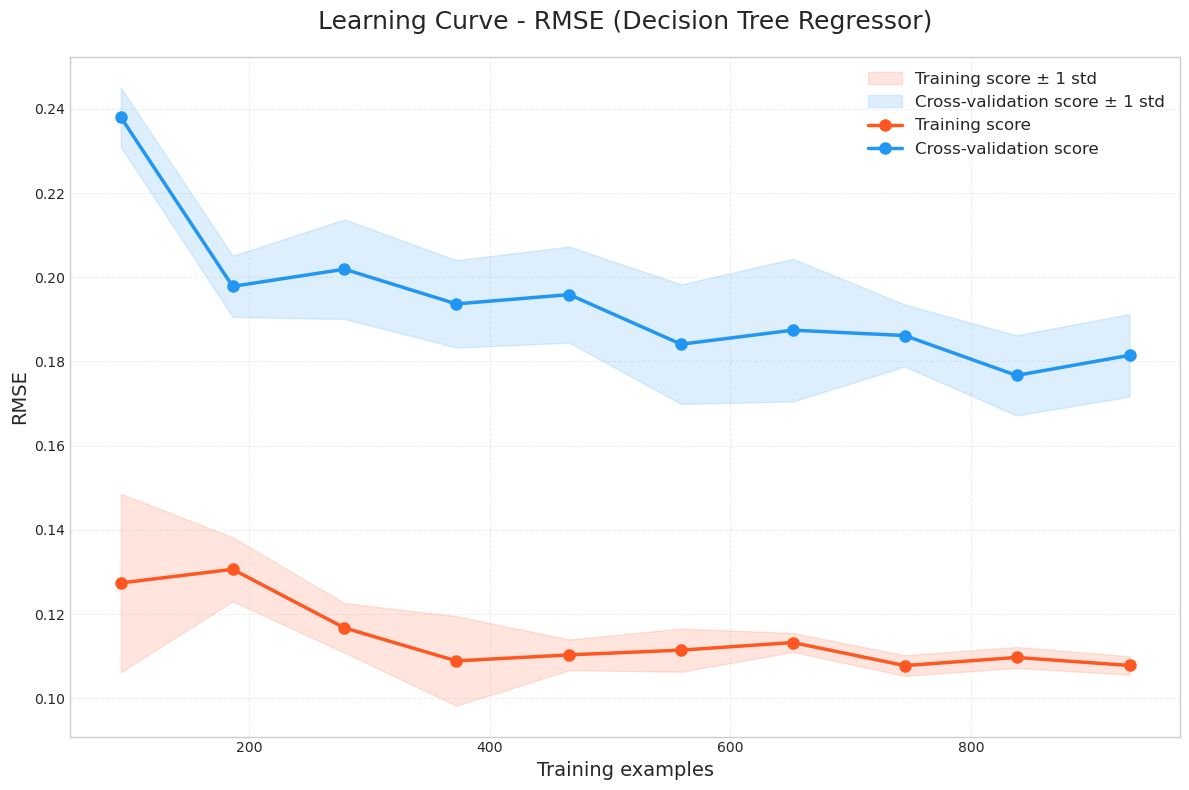

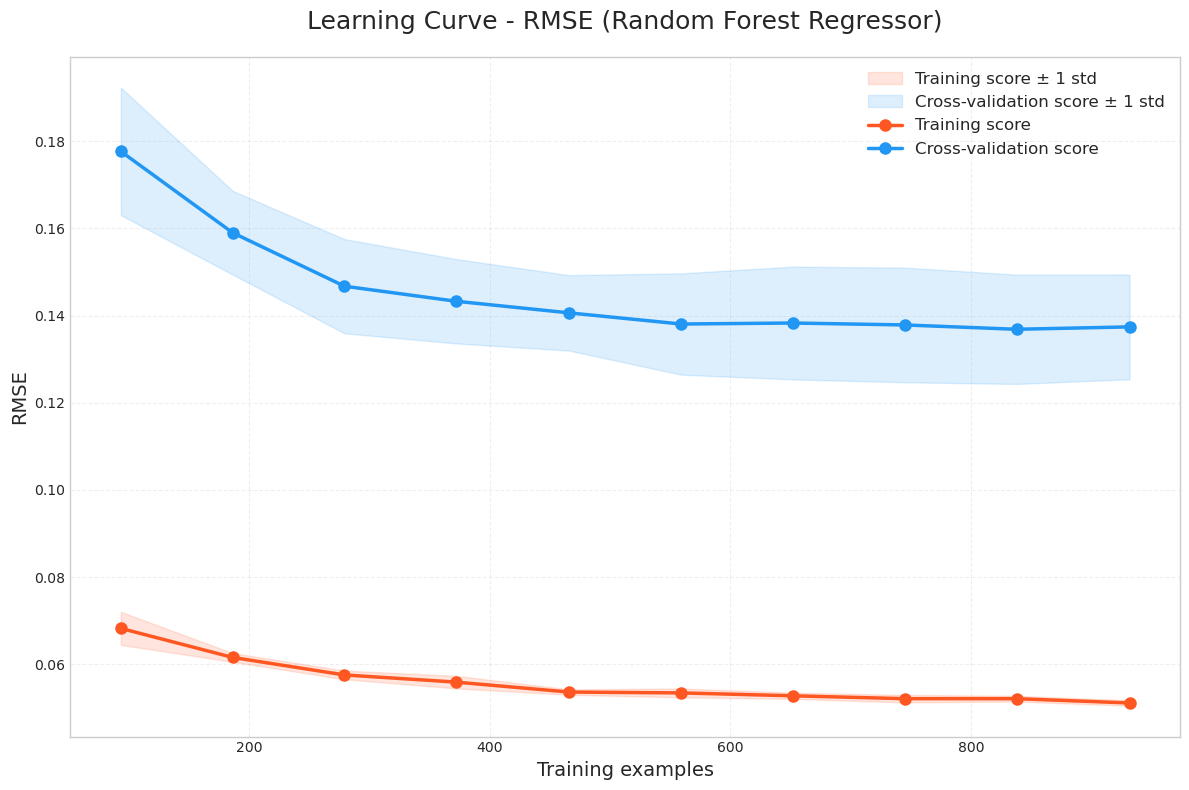

In [25]:
# Plot RMSE learning curves
print("Generating RMSE learning curves...")
plot_learning_curve(best_dt, X_train_array, y_train_array, 
                   "Learning Curve - RMSE (Decision Tree Regressor)", 
                   metric="rmse")
# plt.savefig('decision_tree_rmse_learning_curve.png', dpi=300, bbox_inches='tight')
plt.show()

plot_learning_curve(best_rf, X_train_array, y_train_array, 
                   "Learning Curve - RMSE (Random Forest Regressor)", 
                   metric="rmse")
# plt.savefig('random_forest_rmse_learning_curve.png', dpi=300, bbox_inches='tight')
plt.show()

## 4.3 Neural Network

Traditional linear models struggle to capture the nonlinear relationships and interaction effects among these factors. Neural networks, with their powerful nonlinear - modeling capabilities and multi - layer feature - learning mechanisms, provide a brand - new perspective for housing - price prediction.

We conduct a neural network model with 3 hidden layer, deep neurons (256-128-64) and batch size 32 to predict house saling price. From the results, the neural network model demonstrates good performance in the housing - price prediction task. The Mean Squared Error (MSE) is 0.0308, the Root Mean Squared Error (RMSE) is 0.1754, and the Mean Absolute Error (MAE) is 0.1226. 

These indicators show that the deviation between the predicted values and the actual values of the model is small. Observing the Loss Curves and MAE Curves, both the Training Loss and Validation Loss drop rapidly at the beginning and then tend to stabilize, and they almost overlap in the end, indicating that the model converges effectively during training without obvious overfitting or underfitting. In the scatter plot of Predicted Price vs Actual Price, most data points are closely distributed near the red line (ideal prediction line), further verifying the accuracy and reliability of the model’s predictions. 

2025-05-11 11:03:35.658444: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-05-11 11:03:35.658489: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-05-11 11:03:35.659320: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-05-11 11:03:35.665352: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-05-11 11:03:37.283617: W tensorflow/compiler/tf2

Epoch 1: loss: 143.4417 - mae: 11.8759 - val_loss: 137.8425 - val_mae: 11.7346
Epoch 20: loss: 4.1567 - mae: 1.5687 - val_loss: 0.5955 - val_mae: 0.5905
Epoch 40: loss: 2.3694 - mae: 1.2122 - val_loss: 0.2311 - val_mae: 0.3482
Epoch 60: loss: 1.6146 - mae: 0.9954 - val_loss: 0.1386 - val_mae: 0.3001
Epoch 80: loss: 1.3300 - mae: 0.9093 - val_loss: 0.0782 - val_mae: 0.2185
Epoch 100: loss: 1.0995 - mae: 0.8110 - val_loss: 0.0442 - val_mae: 0.1571
Epoch 120: loss: 0.8620 - mae: 0.7415 - val_loss: 0.0261 - val_mae: 0.1244
Epoch 140: loss: 0.7469 - mae: 0.6829 - val_loss: 0.0491 - val_mae: 0.1771
Epoch 160: loss: 0.6842 - mae: 0.6505 - val_loss: 0.0326 - val_mae: 0.1343

Training completed. Total epochs: 164
10/10 [==============================] - 0s 1ms/step

Test Results:
Mean Squared Error (MSE): 0.0308
Root Mean Squared Error (RMSE): 0.1754
Mean Absolute Error (MAE): 0.1266


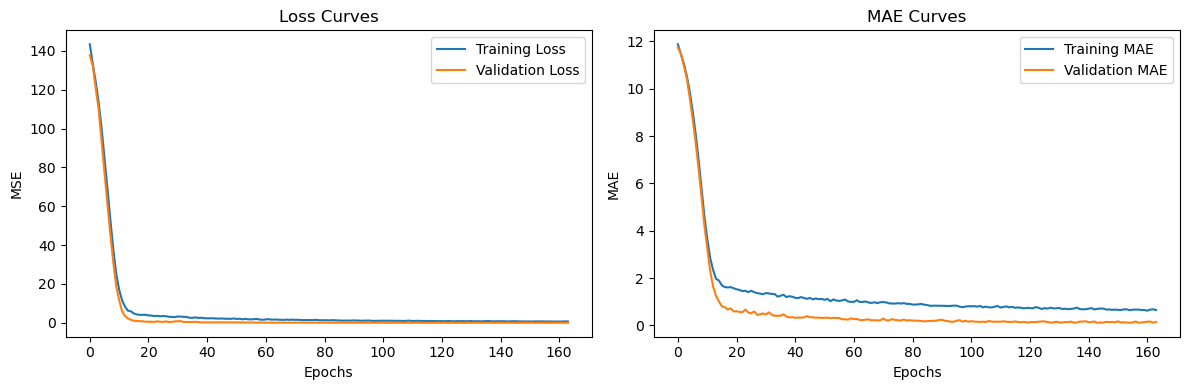

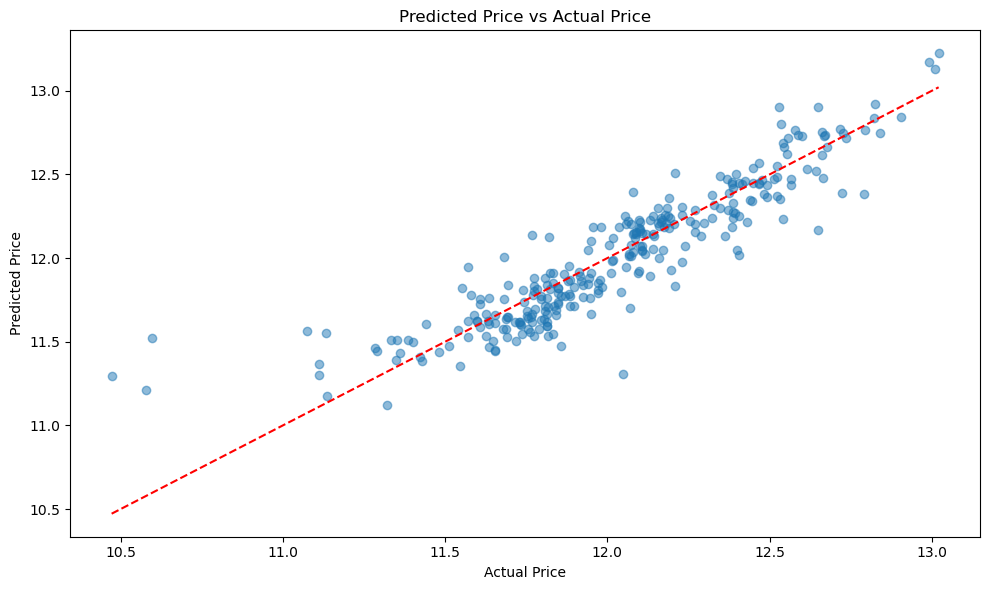

In [9]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, Callback

# Prepare data
X_train_array = X_train.values.astype('float32')
X_test_array = X_test.values.astype('float32')
y_train_array = y_train.values.astype('float32')
y_test_array = y_test.values.astype('float32')

# control output frequency
class PeriodicLogger(Callback):
    def __init__(self, display_freq=20):
        self.display_freq = display_freq
        
    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0 or (epoch + 1) % self.display_freq == 0:
            print(f"Epoch {epoch + 1}: loss: {logs['loss']:.4f} - "
                  f"mae: {logs['mae']:.4f} - "
                  f"val_loss: {logs['val_loss']:.4f} - "
                  f"val_mae: {logs['val_mae']:.4f}")

# Define model architecture
input_dim = X_train_array.shape[1]

model = keras.Sequential([
    layers.Dense(256, activation='relu', input_shape=(input_dim,)),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(1)
])

# Compile model
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Create callbacks
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True,
    verbose=0  # Turn off early stopping verbose output
)

periodic_logger = PeriodicLogger(display_freq=20)

# Fit the model
history = model.fit(
    X_train_array, y_train_array,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping, periodic_logger],
    verbose=0  # Turn off default output
)

# Display training completion info
print(f"\nTraining completed. Total epochs: {len(history.history['loss'])}")

# Model evaluation
y_pred = model.predict(X_test_array)
mse = mean_squared_error(y_test_array, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_array, y_pred)

print(f"\nTest Results:")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

# Visualization
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.legend()
plt.title('Loss Curves')

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()
plt.title('MAE Curves')

plt.tight_layout()
plt.show()

# Visualize prediction results
plt.figure(figsize=(10, 6))
plt.scatter(y_test_array, y_pred, alpha=0.5)
plt.plot([y_test_array.min(), y_test_array.max()], [y_test_array.min(), y_test_array.max()], 'r--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Predicted Price vs Actual Price')
plt.tight_layout()
plt.show()

Adjusting the parameter to a shallower neural network model with less neurons (68-32-16), less bathch size (16) and L1 regularization, the results seem to be better with MSE 0.0269, RMSE 0.1641 and MAE 0.1217. 

Deeper network structure may capture more complex nonlinear relationships and could perform better with large datasets and complex feature relationships. Shallower network structure L1 regularization may drive some weights to zero, making the model sparser and providing both prediction accuracy and feature selection capabilities (interpretability). For this housing - price predicting task, both models fit well.

Epoch 1: loss: 144.7465 - mae: 11.9170 - val_loss: 136.3406 - val_mae: 11.6349
Epoch 20: loss: 13.7635 - mae: 3.2134 - val_loss: 9.9919 - val_mae: 2.8137
Epoch 40: loss: 3.0538 - mae: 1.2205 - val_loss: 1.0210 - val_mae: 0.4387
Epoch 60: loss: 2.3127 - mae: 1.0209 - val_loss: 0.7892 - val_mae: 0.2924
Epoch 80: loss: 1.8685 - mae: 0.9100 - val_loss: 0.6965 - val_mae: 0.2285
Epoch 100: loss: 1.6696 - mae: 0.8305 - val_loss: 0.6190 - val_mae: 0.1901
Epoch 120: loss: 1.5856 - mae: 0.8296 - val_loss: 0.5257 - val_mae: 0.1393
Epoch 140: loss: 1.4421 - mae: 0.7886 - val_loss: 0.4481 - val_mae: 0.1236
Epoch 160: loss: 1.3547 - mae: 0.7802 - val_loss: 0.3785 - val_mae: 0.1203
Epoch 180: loss: 1.2750 - mae: 0.7851 - val_loss: 0.3153 - val_mae: 0.1299
Epoch 200: loss: 1.1535 - mae: 0.7607 - val_loss: 0.2564 - val_mae: 0.1192

Training completed. Total epochs: 200
10/10 [==============================] - 0s 1ms/step

Test Results:
Mean Squared Error (MSE): 0.0269
Root Mean Squared Error (RMSE): 0.

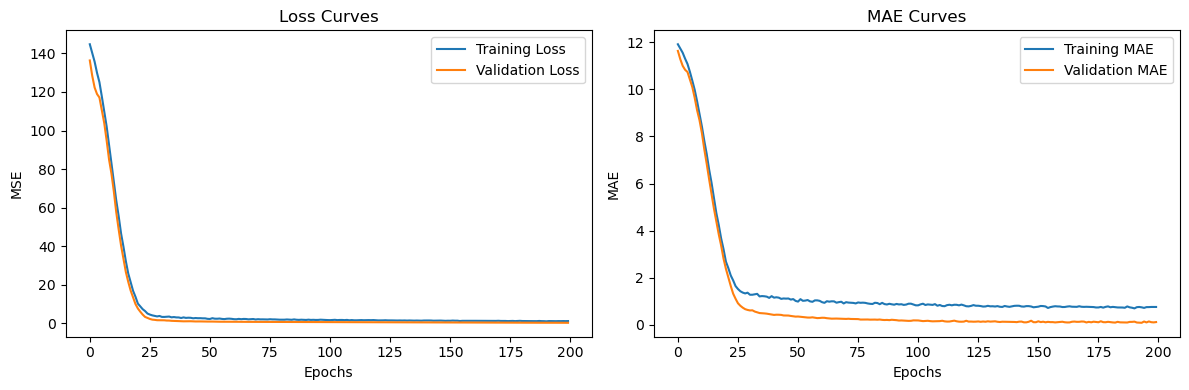

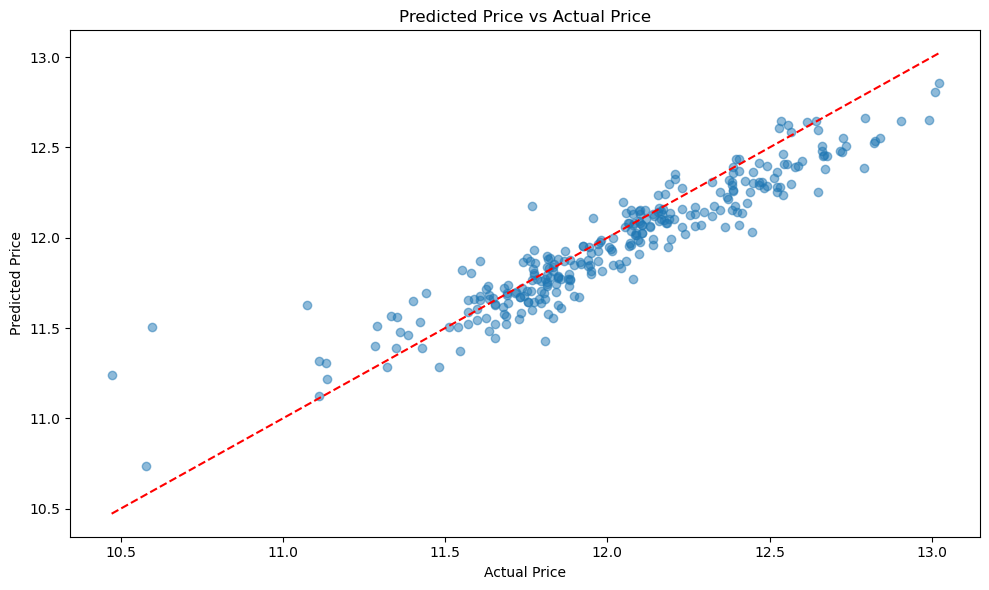

In [6]:
from tensorflow.keras import regularizers

# Define model architecture
input_dim = X_train_array.shape[1]
model = keras.Sequential([
    layers.Dense(64, activation='relu', 
                kernel_regularizer=regularizers.l1(0.000509),
                input_shape=(input_dim,)),
    layers.BatchNormalization(),
    layers.Dropout(0.1),
    layers.Dense(32, activation='relu', 
                 kernel_regularizer=regularizers.l1(0.0005)
                ),
    layers.BatchNormalization(),
    layers.Dropout(0.1),
    layers.Dense(16, activation='relu', 
                kernel_regularizer=regularizers.l1(0.0005)
                ),
    layers.BatchNormalization(),
    layers.Dropout(0.1),
    layers.Dense(1)
])

optimizer = keras.optimizers.Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

# Add early stopping and learning rate reduction callbacks
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=20, restore_best_weights=True, verbose=0
)
lr_scheduler = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=10, min_lr=0.00001, verbose=0
)

periodic_logger = PeriodicLogger(display_freq=20)

# Train model
history = model.fit(
    X_train_array, y_train_array,
    epochs=200,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stopping, lr_scheduler, periodic_logger],
    verbose=0  # Turn off default output
)

# Display training completion info
print(f"\nTraining completed. Total epochs: {len(history.history['loss'])}")

# Model evaluation
y_pred = model.predict(X_test_array)
mse = mean_squared_error(y_test_array, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_array, y_pred)

print(f"\nTest Results:")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

# Visualization
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.legend()
plt.title('Loss Curves')

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()
plt.title('MAE Curves')

plt.tight_layout()
plt.show()

# Visualize prediction results
plt.figure(figsize=(10, 6))
plt.scatter(y_test_array, y_pred, alpha=0.5)
plt.plot([y_test_array.min(), y_test_array.max()], [y_test_array.min(), y_test_array.max()], 'r--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Predicted Price vs Actual Price')
plt.tight_layout()
plt.show()

The neural network model with features selected by Lasso demonstrates excellent performance in the housing - price prediction task. The Mean Squared Error (MSE) is 0.0309, the Root Mean Squared Error (RMSE) is 0.1758, and the Mean Absolute Error (MAE) is 0.1269. These indicators show that the deviation between the model’s predicted values and the actual values is extremely small. Lasso feature selection effectively removes redundant features, enhancing the model’s generalization ability and prediction accuracy, providing a more reliable solution for housing - price prediction. 

In [10]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, Callback
# Use lasso selected features to train neural network model
X_train_selected_array = X_train_selected.values.astype('float32')
X_test_selected_array = X_test_selected.values.astype('float32')

input_dim_selected = X_train_selected_array.shape[1]
print(f"{input_dim_selected} features are selected by Lasso")

model_selected = keras.Sequential([
    layers.Dense(64, activation='relu', 
                input_shape=(input_dim_selected,)),
    layers.BatchNormalization(),
    layers.Dropout(0.05),
    layers.Dense(32, activation='relu',),
    layers.BatchNormalization(),
    layers.Dropout(0.05),
    layers.Dense(16, activation='relu',),
    layers.BatchNormalization(),
    layers.Dropout(0.05),
    layers.Dense(1)
])

optimizer = keras.optimizers.Adam(learning_rate=0.001)
model_selected.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=20, restore_best_weights=True, verbose=0
)
lr_scheduler = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=10, min_lr=0.00001, verbose=0
)

# Use the PeriodicLogger class defined previously
periodic_logger = PeriodicLogger(display_freq=20)

history_selected = model_selected.fit(
    X_train_selected_array, y_train_array,
    epochs=200,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stopping, lr_scheduler, periodic_logger],
    verbose=0  # Turn off default output
)

# Display training completion info
print(f"\nTraining completed. Total epochs: {len(history_selected.history['loss'])}")

y_pred_selected = model_selected.predict(X_test_selected_array)
mse_selected = mean_squared_error(y_test_array, y_pred_selected)
rmse_selected = np.sqrt(mse_selected)
mae_selected = mean_absolute_error(y_test_array, y_pred_selected)

print(f"\nThe performance of the neural network model with Lasso selected features:")
print(f"Mean Squared Error (MSE): {mse_selected:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_selected:.4f}")
print(f"Mean Absolute Error (MAE): {mae_selected:.4f}")

104 features are selected by Lasso
Epoch 1: loss: 142.3465 - mae: 11.8943 - val_loss: 137.0366 - val_mae: 11.6975
Epoch 20: loss: 1.1567 - mae: 0.8123 - val_loss: 0.4320 - val_mae: 0.3599
Epoch 40: loss: 0.7620 - mae: 0.6737 - val_loss: 0.1014 - val_mae: 0.2148
Epoch 60: loss: 0.6330 - mae: 0.6145 - val_loss: 0.0597 - val_mae: 0.1570
Epoch 80: loss: 0.6265 - mae: 0.6231 - val_loss: 0.0481 - val_mae: 0.1415
Epoch 100: loss: 0.5235 - mae: 0.5801 - val_loss: 0.0386 - val_mae: 0.1429
Epoch 120: loss: 0.5675 - mae: 0.5851 - val_loss: 0.0321 - val_mae: 0.1221
Epoch 140: loss: 0.5356 - mae: 0.5873 - val_loss: 0.0320 - val_mae: 0.1260

Training completed. Total epochs: 155
10/10 [==============================] - 0s 880us/step

The performance of the neural network model with Lasso selected features:
Mean Squared Error (MSE): 0.0309
Root Mean Squared Error (RMSE): 0.1758
Mean Absolute Error (MAE): 0.1269


## 4.4 Gradient Boosting

Gradient Boosting, an iterative decision tree ensemble technique, sequentially builds weak learners by focusing on the residuals of previous models, progressively optimizing overall predictive performance. Unlike the parallel ensemble strategy of random forests, gradient boosting operates in a sequential manner, constructing each new model in the direction of minimizing the gradient of the loss function, thereby effectively capturing complex nonlinear relationships and high - order interaction effects in data.

In [30]:
!conda install -c conda-forge xgboost -y

Channels:
 - conda-forge
 - defaults
Platform: win-64
Solving environment: ...working... done

# All requested packages already installed.



We run an eXtreme Gradient Boosting algorithm, find features like OverallQual, TotalSF, QualScore and GarageCars are most important. The plot exhibits the ideal situation where the predicted value equals the actual value. Most of the blue dots are concentrated near the red line, suggesting that the predicted values are close to the actual values, indicating good model performance.

Starting grid search...
Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 4, 'min_child_weight': 3, 'n_estimators': 200, 'n_jobs': -1, 'subsample': 0.8, 'tree_method': 'hist'}
Best CV RMSE: 0.1200

Training final model...

Test RMSE: 0.1232
Test MAE: 0.0803

Top 10 Important Features:
         Feature  Importance
     OverallQual    0.215075
         TotalSF    0.115147
       QualScore    0.103579
      GarageCars    0.058246
     MSZoning_RM    0.033714
     KitchenQual    0.026906
    CentralAir_Y    0.023574
       TotalBath    0.022332
       GrLivArea    0.015090
GarageFinish_Unf    0.014631


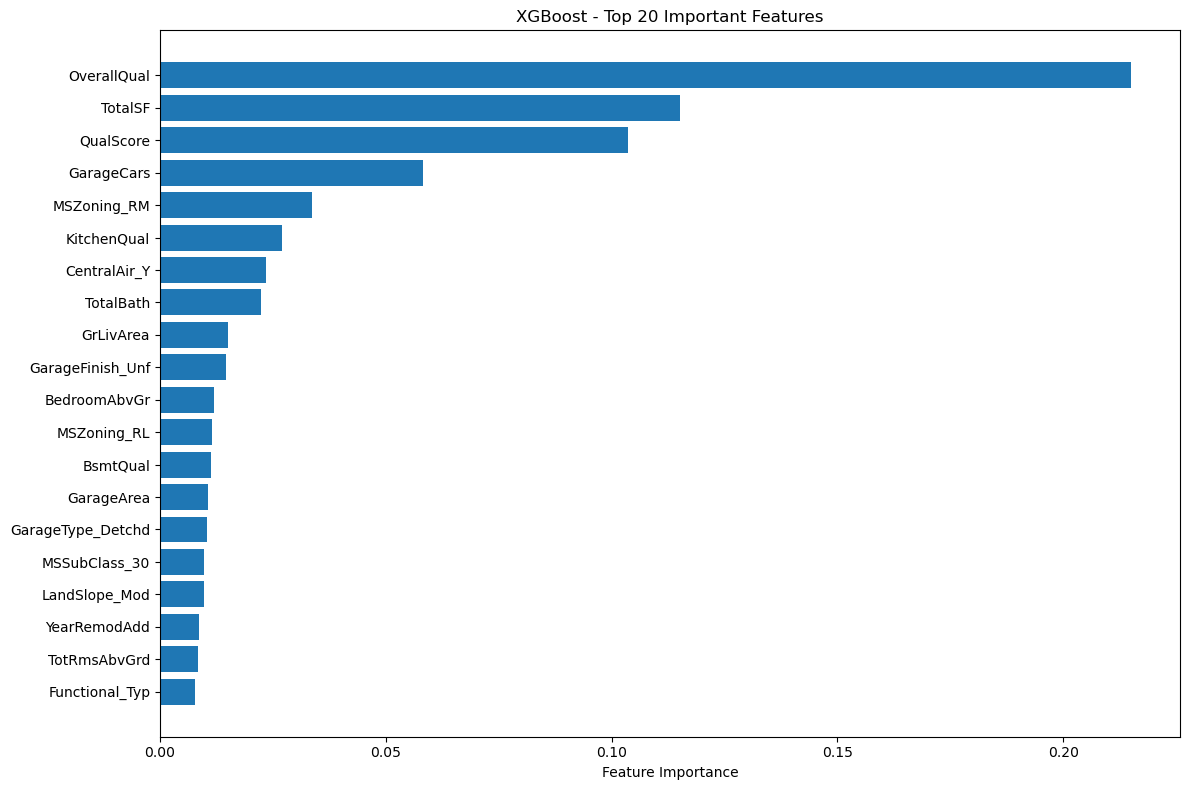

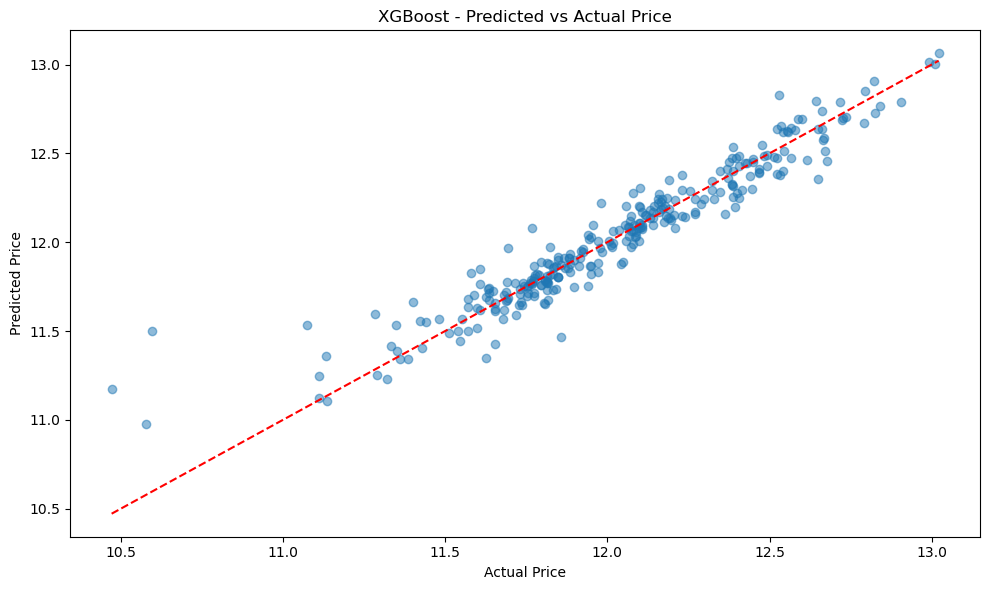

In [31]:
import xgboost as xgb

# Data preparation
y_train_array = y_train.values.ravel() 
y_test_array = y_test.values.ravel()
X_train_array = X_train.values
X_test_array = X_test.values

# Parameter grid
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [4, 6],
    'min_child_weight': [1, 3],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'n_jobs': [-1],
    'tree_method': ['hist'],
}

# Grid search
cv = KFold(n_splits=3, shuffle=True, random_state=42)
xgb_base = xgb.XGBRegressor(random_state=42, objective='reg:squarederror', verbosity=0)

print("Starting grid search...")
grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_mean_squared_error',
    verbose=0,
    n_jobs=-1
)

grid_search.fit(X_train_array, y_train_array)
best_params = grid_search.best_params_
print(f"Best parameters: {best_params}")
print(f"Best CV RMSE: {np.sqrt(-grid_search.best_score_):.4f}")

# Train final model
print("\nTraining final model...")
best_xgb_model = xgb.XGBRegressor(**best_params, random_state=42)
best_xgb_model.fit(X_train_array, y_train_array)

# Predictions and metrics
y_pred = best_xgb_model.predict(X_test_array)
rmse = np.sqrt(mean_squared_error(y_test_array, y_pred))
mae = mean_absolute_error(y_test_array, y_pred)

print(f"\nTest RMSE: {rmse:.4f}")
print(f"Test MAE: {mae:.4f}")

# Feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_xgb_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 10 Important Features:")
print(feature_importance.head(10).to_string(index=False))

# Visualizations
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Feature Importance')
plt.title('XGBoost - Top 20 Important Features')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.scatter(y_test_array, y_pred, alpha=0.5)
plt.plot([y_test_array.min(), y_test_array.max()], 
         [y_test_array.min(), y_test_array.max()], 'r--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('XGBoost - Predicted vs Actual Price')
plt.tight_layout()
plt.show()

# 5 Reflection and Conclusion


Conclusions: To sum up, in the explanatory data analysis part, we find that there exists strong correlations between the rates of the overall material and finish of the house, above grade (ground) living area square feet and house price. And through PCA, we reduce features to 63, with PC1 for quantity and PC2 for square measure, aiding feature engineering. Finally, in the prediction part, firstly, with regression methods, we find that LASSO has better performance with 0.1216 testing RMSE compared with OLS; secondly, in non-linear models, random forest shows better result than decision trees and neural networks, with 0.1641 testing RMSE.  
Limitations: There are also some limitations in our analysis. For example, due to the limitations of the computer performance, some more advanced algorithms cannot be finished running. If possible, in the future we can try to take advantage of the remote computer in campus to make up this regret. In addition, due to the restriction of time and cost, our sample data is only limited to Ames, a small city in Iowa, which means that the results may be not general for other places. Therefore, in the future we will try to find more datasets in different places to verify whether our discovery is universal.

# 6 Team Contribution 

Yanze SHAO & Qizhou TU: charge for data preprocessing and data analysis, make the PPT and do the presentation.  
Pengbin YU & Yinuo ZHANG: charge for the data collation and summary, improve the process of data analysis and write the final report.
